In [1]:
import pandas as pd
import numpy as np
import os
import pyreadstat

from pathlib import Path
file_path = Path("LLCP2023.XPT")

print("文件路径：", file_path.resolve())
print("文件是否存在：", file_path.exists())

文件路径： C:\Users\Suzy\Desktop\CityU\Course\5001\Project\LLCP2023.XPT
文件是否存在： True


In [2]:
# 1. 定义项目需要的变量
ace_vars = [
    "ACEDEPRS", "ACEDRINK", "ACEDRUGS", "ACEPRISN",
    "ACEDIVRC", "ACEPUNCH", "ACEHURT1", "ACESWEAR",
    "ACETOUCH", "ACETTHEM", "ACEHVSEX"
]

scd_vars = ["CIMEMLO1", "CDWORRY", "CDDISCU1", "CDHOUS1", "CDSOCIA1"]

demo_vars = ["SEXVAR", "_AGE80", "EDUCA", "INCOME3", "MARITAL", "_STATE"]

# Race / Ethnicity
race_vars = ["_RACEGR3"]

# Health conditions and health behaviors
health_vars = [
    "_BMI5CAT",    # BMI category
    "DIABETE4",    # Diabetes
    "ADDEPEV3",    # Depression
    "CVDSTRK3",    # Stroke
    "_RFHYPE6",     # High blood pressure
    "_SMOKER3",    # Smoking status
    "_TOTINDA"     # Physical activity
]

survey_vars = ["_LLCPWT", "_STSTR", "_PSU"]

use_vars = list(dict.fromkeys(
    ace_vars + scd_vars + demo_vars +
    race_vars + health_vars + survey_vars
))

# 2. 读取数据
df_raw, meta = pyreadstat.read_xport(
    file_path,
    encoding="latin1",
    usecols=use_vars
)

print("数据读取完成")

数据读取完成


In [3]:
# SCD 和 ACE 变量处理、样本筛选及总分计算
# 1. 创建 SCD 二元变量
# CIMEMLO1: 1 = Yes, 2 = No；其他回答视为无效
df_raw["SCD"] = df_raw["CIMEMLO1"].map({
    1: 1,
    2: 0
})

# 2. 将 5 个是/否 ACE 变量统一编码
# 1 = Yes，2 = No；其他编码转为缺失值
yes_no_vars = [
    "ACEDEPRS", "ACEDRINK", "ACEDRUGS",
    "ACEPRISN", "ACEDIVRC"
]

for var in yes_no_vars:
    df_raw[var + "_bin"] = df_raw[var].map({
        1: 1,
        2: 0
    })

# 3. 将 6 个频率型 ACE 变量统一编码
# 1 = Never；2 或 3 = 曾有相关经历
frequency_vars = [
    "ACEPUNCH", "ACEHURT1", "ACESWEAR",
    "ACETOUCH", "ACETTHEM", "ACEHVSEX"
]

for var in frequency_vars:
    df_raw[var + "_bin"] = df_raw[var].map({
        1: 0,
        2: 1,
        3: 1
    })

# 汇总 11 个 ACE 二元变量
ace_binary_vars = [
    var + "_bin" for var in yes_no_vars + frequency_vars
]

# 4. 检查 11 个 ACE 变量是否存在
missing_ace_vars = [
    var for var in ace_binary_vars
    if var not in df_raw.columns
]

if missing_ace_vars:
    raise ValueError(f"缺少 ACE 变量：{missing_ace_vars}")

# 5. 统计样本筛选过程
n_all = len(df_raw)

age_mask = df_raw["_AGE80"] >= 45
scd_mask = df_raw["SCD"].notna()

# 11 项 ACE 均必须有有效编码
ace_complete_mask = df_raw[ace_binary_vars].notna().all(axis=1)

age_scd_mask = age_mask & scd_mask
final_mask = age_scd_mask & ace_complete_mask

sample_flow = pd.DataFrame({
    "筛选阶段": [
        "原始数据",
        "年龄至少 45 岁",
        "年龄至少 45 岁且 SCD 有效",
        "年龄至少 45 岁、SCD 有效且 11 项 ACE 均有效"
    ],
    "样本量": [
        n_all,
        int(age_mask.sum()),
        int(age_scd_mask.sum()),
        int(final_mask.sum())
    ]
})

sample_flow["相比上一阶段减少人数"] = (
    sample_flow["样本量"].shift(1) - sample_flow["样本量"]
).fillna(0).astype(int)

print("样本筛选过程：")
display(sample_flow)

# 6. 创建最终分析样本
analysis_df = df_raw.loc[final_mask].copy()

# 检查 11 项 ACE 是否均只有 0 和 1
ace_values_ok = analysis_df[ace_binary_vars].isin([0, 1]).all().all()

print("当前分析样本量：", len(analysis_df))
print("11 项 ACE 是否均只有 0 和 1：", ace_values_ok)

if not ace_values_ok:
    raise ValueError("ACE 变量存在缺失或无效编码，请检查数据筛选步骤。")

# 7. 创建统一的 ACE 总分变量
analysis_df["ACE_score_11"] = (
    analysis_df[ace_binary_vars].sum(axis=1).astype(int)
)

print(
    "ACE 总分范围：",
    analysis_df["ACE_score_11"].min(),
    "到",
    analysis_df["ACE_score_11"].max()
)

# 同步创建清理后的分析数据集
analysis_clean = analysis_df.copy()

# 8. 查看 SCD 分布
print("\nSCD 分布：")
display(
    analysis_clean["SCD"]
    .value_counts()
    .sort_index()
    .rename(index={0: "No SCD", 1: "SCD"})
    .to_frame("人数")
)

# 9. 查看 11 项 ACE 总分分布
print("\n11 项 ACE 总分分布：")
display(
    analysis_clean["ACE_score_11"]
    .value_counts()
    .sort_index()
    .to_frame("人数")
)

# 10. 查看不同 ACE 总分下的 SCD 比例（未加权）
scd_by_ace = (
    analysis_clean.groupby("ACE_score_11")["SCD"]
    .agg(["count", "mean"])
    .rename(columns={
        "count": "样本量",
        "mean": "SCD比例"
    })
)

scd_by_ace["SCD比例（%）"] = (
    scd_by_ace["SCD比例"] * 100
).round(2)

print("\n不同 ACE 总分下的 SCD 比例（未加权）：")
display(scd_by_ace)


样本筛选过程：


,筛选阶段,样本量,相比上一阶段减少人数
0,原始数据,433323,0
1,年龄至少 45 岁,304741,128582
2,年龄至少 45 岁且 SCD 有效,133857,170884
3,年龄至少 45 岁、SCD 有效且 11 项 ACE 均有效,35754,98103


当前分析样本量： 35754
11 项 ACE 是否均只有 0 和 1： True
ACE 总分范围： 0 到 11

SCD 分布：


,人数
SCD,
No SCD,29641
SCD,6113



11 项 ACE 总分分布：


,人数
ACE_score_11,
0,14342
1,8245
2,4626
3,3023
4,2005
5,1317
6,890
7,578
8,359



不同 ACE 总分下的 SCD 比例（未加权）：


,样本量,SCD比例,SCD比例（%）
ACE_score_11,,,
0,14342,0.115953,11.60
1,8245,0.153548,15.35
2,4626,0.196066,19.61
3,3023,0.217003,21.70
4,2005,0.245885,24.59
5,1317,0.273349,27.33
6,890,0.325843,32.58
7,578,0.325260,32.53
8,359,0.342618,34.26


In [4]:
# 人口学变量处理
# 1. 复制当前分析数据，避免修改 analysis_df
analysis_clean = analysis_df.copy()

# 2. 将人口学变量中的特殊编码转换为缺失值
# 不删除整行，只把无效回答标记为缺失

analysis_clean["EDUCA"] = analysis_clean["EDUCA"].replace({
    9: np.nan
})

analysis_clean["INCOME3"] = analysis_clean["INCOME3"].replace({
    77: np.nan,
    99: np.nan
})

analysis_clean["MARITAL"] = analysis_clean["MARITAL"].replace({
    9: np.nan
})

analysis_clean["_RACEGR3"] = analysis_clean["_RACEGR3"].replace({
    9: np.nan
})

# 3. 检查清理后的变量
demographic_vars = [
    "SEXVAR", "_AGE80", "EDUCA",
    "INCOME3", "MARITAL", "_STATE","_RACEGR3"
]

print("人口学变量清理后，缺失值数量：")
display(analysis_clean[demographic_vars].isna().sum().to_frame("缺失数量"))

print("\n人口学变量清理后，缺失值比例（%）：")
display(
    (analysis_clean[demographic_vars].isna().mean() * 100)
    .round(2)
    .to_frame("缺失比例（%）")
)

# 4. 查看几个主要人口学变量的分布
for var in ["SEXVAR", "EDUCA", "INCOME3", "MARITAL"]:
    print(f"\n{var} 的频数分布：")
    display(
        analysis_clean[var]
        .value_counts(dropna=False)
        .sort_index()
        .to_frame("人数")
    )



人口学变量清理后，缺失值数量：


,缺失数量
SEXVAR,0
_AGE80,0
EDUCA,96
INCOME3,6418
MARITAL,216
_STATE,0
_RACEGR3,639



人口学变量清理后，缺失值比例（%）：


,缺失比例（%）
SEXVAR,0.00
_AGE80,0.00
EDUCA,0.27
INCOME3,17.95
MARITAL,0.60
_STATE,0.00
_RACEGR3,1.79



SEXVAR 的频数分布：


,人数
SEXVAR,
1.0,15627
2.0,20127


... (2 outputs left out)


INCOME3 的频数分布：


,人数
INCOME3,
1.0,603
2.0,874
3.0,1124
4.0,1671
5.0,3287
6.0,3865
7.0,4878
8.0,4277
9.0,4381



MARITAL 的频数分布：


,人数
MARITAL,
1.0,20022
2.0,5477
3.0,5965
4.0,588
5.0,2735
6.0,751
NaN,216


In [5]:
# health conditions and health behaviors cleaning

# 1. BMI category
# _BMI5CAT:
# 1 = Underweight
# 2 = Normal weight
# 3 = Overweight
# 4 = Obese
# Missing values are already represented as NaN

# 2. Diabetes
# DIABETE4:
# 7 = Don't know / Not sure
# 9 = Refused
analysis_clean["DIABETE4"] = analysis_clean["DIABETE4"].replace({
    7: np.nan,
    9: np.nan
})

# 3. Depression
# ADDEPEV3: 1 = Yes, 2 = No
analysis_clean["ADDEPEV3"] = analysis_clean["ADDEPEV3"].replace({
    7: np.nan,
    9: np.nan
})
# Depression: 1 = Yes, 0 = No
analysis_clean["Depression_bin"] = analysis_clean["ADDEPEV3"].map({
    1: 1,
    2: 0
})

# 4. Stroke
# CVDSTRK3: 1 = Yes, 2 = No
analysis_clean["CVDSTRK3"] = analysis_clean["CVDSTRK3"].replace({
    7: np.nan,
    9: np.nan
})
# Stroke: 1 = Yes, 0 = No
analysis_clean["Stroke_bin"] = analysis_clean["CVDSTRK3"].map({
    1: 1,
    2: 0
})

# 5. High blood pressure
# Keep valid response categories; remove DK / Refused
analysis_clean["_RFHYPE6"] = analysis_clean["_RFHYPE6"].replace({
    9: np.nan
})
# Yes = 1, No = 0
analysis_clean["HighBP_bin"] = analysis_clean["_RFHYPE6"].map({
    1: 0,
    2: 1
})

# 6. Smoking status
# _SMOKER3: 1-4 are valid smoking categories
# 9 = Missing / unknown
analysis_clean["_SMOKER3"] = analysis_clean["_SMOKER3"].replace({
    9: np.nan
})

# 7. Physical activity
# _TOTINDA: 1 = Yes, 2 = No, 9 = DK / Refused / Missing
analysis_clean["_TOTINDA"] = analysis_clean["_TOTINDA"].replace({
    9: np.nan
})
# Physical activity: 1 = Yes, 0 = No
analysis_clean["PhysicalActivity_bin"] = analysis_clean["_TOTINDA"].map({
    1: 1,
    2: 0
})

# 8. Check missing values
missing_summary = pd.DataFrame({
    "Variable": health_vars,
    "Missing_Count": [
        analysis_clean[v].isna().sum() for v in health_vars
    ],
    "Missing_Percent": [
        round(analysis_clean[v].isna().mean() * 100, 2)
        for v in health_vars
    ]
})
display(missing_summary)

# 10. Check frequency distributions
for var in health_vars:
    print(f"\n{var} frequency distribution:")
    display(
        analysis_clean[var]
        .value_counts(dropna=False)
        .sort_index()
        .to_frame("Count")
    )

,Variable,Missing_Count,Missing_Percent
0,_BMI5CAT,1814,5.07
1,DIABETE4,47,0.13
2,ADDEPEV3,123,0.34
3,CVDSTRK3,122,0.34
4,_RFHYPE6,119,0.33
5,_SMOKER3,241,0.67
6,_TOTINDA,89,0.25



_BMI5CAT frequency distribution:


,Count
_BMI5CAT,
1.0,481
2.0,9579
3.0,12536
4.0,11344
NaN,1814



DIABETE4 frequency distribution:


,Count
DIABETE4,
1.0,6946
2.0,185
3.0,27617
4.0,959
NaN,47



ADDEPEV3 frequency distribution:


... (5 outputs left out)


_SMOKER3 frequency distribution:


,Count
_SMOKER3,
1.0,2865
2.0,986
3.0,11652
4.0,20010
NaN,241



_TOTINDA frequency distribution:


,Count
_TOTINDA,
1.0,25780
2.0,9885
NaN,89


In [6]:
# 数据质量检查
# 1. 检查必要变量是否存在
required_vars = [
    "SCD", "ACE_score_11",
    "SEXVAR", "_AGE80", "EDUCA",
    "INCOME3", "MARITAL", "_STATE", "_RACEGR3",

    # Health variables
    "_BMI5CAT", "DIABETE4", "ADDEPEV3",
    "CVDSTRK3", "_RFHYPE6", "_SMOKER3", "_TOTINDA",
    
    # Derived binary health variables
    "Depression_bin",
    "Stroke_bin",
    "PhysicalActivity_bin",
    "HighBP_bin",
]

survey_vars = ["_LLCPWT", "_STSTR", "_PSU"]

missing_required = [
    var for var in required_vars
    if var not in analysis_clean.columns
]

missing_survey = [
    var for var in survey_vars
    if var not in analysis_clean.columns
]

print("缺少的必要分析变量：", missing_required)
print("缺少的调查设计变量：", missing_survey)

# 2. 检查年龄筛选是否正确
print(
    "\n所有受访者年龄是否均至少为45岁：",
    analysis_clean["_AGE80"].ge(45).all()
)

# 3. 检查 SCD 是否只包含 0 和 1
scd_values = set(analysis_clean["SCD"].dropna().unique())

print("SCD 的实际取值：", sorted(scd_values))
print(
    "SCD 是否只包含 0 和 1：",
    scd_values.issubset({0, 1})
)

# 4. 检查11个ACE二元变量是否都只有0和1
invalid_ace_values = {}

for var in ace_binary_vars:
    if var not in analysis_clean.columns:
        invalid_ace_values[var] = "变量不存在"
    else:
        values = set(analysis_clean[var].dropna().unique())
        if not values.issubset({0, 1}):
            invalid_ace_values[var] = sorted(values)

print("\nACE二元变量中的异常取值：", invalid_ace_values)
print(
    "11个ACE变量是否全部只有0和1：",
    len(invalid_ace_values) == 0
)

# 5. 检查ACE总分是否等于11项ACE之和
recalculated_score = analysis_clean[ace_binary_vars].sum(axis=1)

score_consistent = (
    recalculated_score == analysis_clean["ACE_score_11"]
).all()

print("\nACE总分是否与11项之和一致：", score_consistent)
print(
    "ACE总分是否均在0到11之间：",
    analysis_clean["ACE_score_11"].between(0, 11).all()
)

# 6. 检查SCD与ACE总分是否存在缺失
print("\nSCD缺失数量：", analysis_clean["SCD"].isna().sum())
print("ACE总分缺失数量：", analysis_clean["ACE_score_11"].isna().sum())

# 7. 检查完全重复的记录
print(
    "\n完全重复的记录数：",
    analysis_clean.duplicated().sum()
)

# 8. 再次检查调查设计变量是否存在
print("\n调查设计变量检查：")
for var in survey_vars:
    if var in analysis_clean.columns:
        print(
            f"{var}: 缺失 {analysis_clean[var].isna().sum()} 条，"
            f"不同取值数 {analysis_clean[var].nunique(dropna=True)}"
        )
    else:
        print(f"{var}: 当前数据中不存在")


缺少的必要分析变量： []
缺少的调查设计变量： []

所有受访者年龄是否均至少为45岁： True
SCD 的实际取值： [np.float64(0.0), np.float64(1.0)]
SCD 是否只包含 0 和 1： True

ACE二元变量中的异常取值： {}
11个ACE变量是否全部只有0和1： True

ACE总分是否与11项之和一致： True
ACE总分是否均在0到11之间： True

SCD缺失数量： 0
ACE总分缺失数量： 0

完全重复的记录数： 0

调查设计变量检查：
_LLCPWT: 缺失 0 条，不同取值数 23270
_STSTR: 缺失 0 条，不同取值数 541
_PSU: 缺失 0 条，不同取值数 10064


In [7]:
# 整理最终分析数据集
# 11 个原始 ACE 变量
ace_raw_vars = yes_no_vars + frequency_vars

final_vars = [
    # 研究结局与 ACE 指标
    "SCD",
    "ACE_score_11",
    *ace_binary_vars,

    # 人口学变量
    "SEXVAR",
    "_AGE80",
    "EDUCA",
    "INCOME3",
    "MARITAL",
    "_STATE",
    "_RACEGR3",

    # Health conditions and health behaviors
    "_BMI5CAT",
    "DIABETE4",
    "ADDEPEV3",
    "CVDSTRK3",
    "_RFHYPE6",
    "_SMOKER3",
    "_TOTINDA",

    "Depression_bin",
    "Stroke_bin",
    "PhysicalActivity_bin",
    "HighBP_bin",
    
    # 原始 ACE 回答
    *ace_raw_vars,
    
    # BRFSS 调查设计变量
    "_LLCPWT",
    "_STSTR",
    "_PSU"
]

# 检查变量是否都存在
missing_vars = [
    var for var in final_vars
    if var not in analysis_clean.columns
]

if missing_vars:
    raise ValueError(f"以下变量不存在，请先检查：{missing_vars}")

# 选择变量并复制
final_df = analysis_clean[final_vars].copy()

print("最终数据集样本量：", len(final_df))
print("最终数据集变量数量：", len(final_df.columns))

display(final_df.head())


最终数据集样本量： 35754
最终数据集变量数量： 45


,SCD,ACE_score_11,ACEDEPRS_bin,ACEDRINK_bin,ACEDRUGS_bin,ACEPRISN_bin,ACEDIVRC_bin,ACEPUNCH_bin,ACEHURT1_bin,ACESWEAR_bin,...,ACEDIVRC,ACEPUNCH,ACEHURT1,ACESWEAR,ACETOUCH,ACETTHEM,ACEHVSEX,_LLCPWT,_STSTR,_PSU
57534,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,2.0,1.0,1.0,1.0,1.0,1.0,1.0,26.615271,101011.0,2.023000e+09
57535,0.0,2,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,66.919532,101011.0,2.023000e+09
57536,0.0,1,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,32.539006,101011.0,2.023000e+09
57537,0.0,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,2.0,1.0,1.0,2.0,1.0,1.0,1.0,56.319382,101011.0,2.023000e+09
57539,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,2.0,1.0,1.0,1.0,1.0,1.0,1.0,21.319514,101011.0,2.023000e+09


In [8]:
# 导出最终分析数据集
output_file = "BRFSS_2023_ACE_SCD_main.csv"

final_df.to_csv(output_file, index=False, encoding="utf-8-sig")

print("文件已导出：", output_file)


文件已导出： BRFSS_2023_ACE_SCD_main.csv


In [9]:
# 生成最终数据集的缺失值报告
missing_report = pd.DataFrame({
    "Variable": final_df.columns,
    "Missing_Count": [
        final_df[col].isna().sum()
        for col in final_df.columns
    ],
    "Missing_Percent": [
        round(final_df[col].isna().mean() * 100, 2)
        for col in final_df.columns
    ]
})

missing_report = missing_report.sort_values(
    by="Missing_Percent",
    ascending=False
)

display(missing_report.head(20))

missing_report.to_csv(
    "BRFSS_2023_ACE_SCD_missingness.csv",
    index=False,
    encoding="utf-8-sig"
)

print("缺失值报告已导出。")


,Variable,Missing_Count,Missing_Percent
16,INCOME3,6418,17.95
20,_BMI5CAT,1814,5.07
19,_RACEGR3,639,1.79
25,_SMOKER3,241,0.67
17,MARITAL,216,0.60
27,Depression_bin,123,0.34
22,ADDEPEV3,123,0.34
23,CVDSTRK3,122,0.34
28,Stroke_bin,122,0.34
24,_RFHYPE6,119,0.33


缺失值报告已导出。


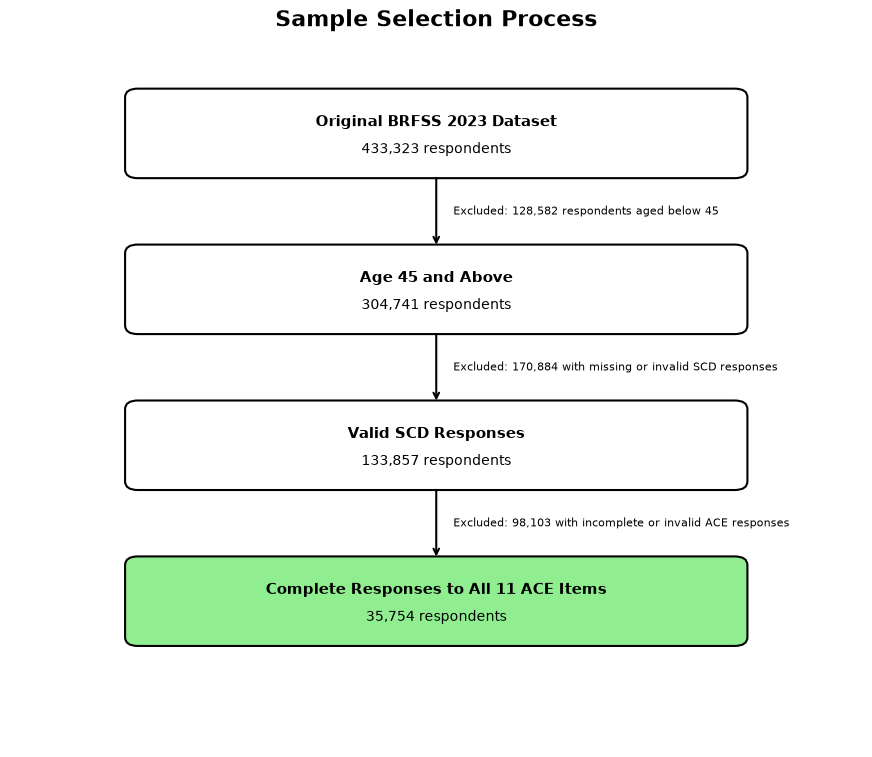

In [10]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

# Sample selection information
steps = [
    ("Original BRFSS 2023 Dataset", "433,323 respondents"),
    ("Age 45 and Above", "304,741 respondents"),
    ("Valid SCD Responses", "133,857 respondents"),
    ("Complete Responses to All 11 ACE Items", "35,754 respondents")
]

excluded = [
    "Excluded: 128,582 respondents aged below 45",
    "Excluded: 170,884 with missing or invalid SCD responses",
    "Excluded: 98,103 with incomplete or invalid ACE responses"
]

fig, ax = plt.subplots(figsize=(11, 9))
ax.set_xlim(0, 10)
ax.set_ylim(0, 12)
ax.axis("off")

box_width = 7
box_height = 1.25
x = 1.5
ys = [10, 7.3, 4.6, 1.9]

for i, ((title, count), y) in enumerate(zip(steps, ys)):

    box = FancyBboxPatch(
        (x, y),
        box_width,
        box_height,
        boxstyle="round,pad=0.15",
        linewidth=1.5,
        edgecolor="black",
        facecolor="white" if i < 3 else "lightgreen"
    )

    ax.add_patch(box)

    ax.text(
        5, y + 0.82,
        title,
        ha="center",
        va="center",
        fontsize=11,
        fontweight="bold"
    )

    ax.text(
        5, y + 0.35,
        count,
        ha="center",
        va="center",
        fontsize=10
    )

    if i < 3:
        arrow_start = y - 0.1
        arrow_end = ys[i + 1] + box_height + 0.1

        ax.annotate(
            "",
            xy=(5, arrow_end),
            xytext=(5, arrow_start),
            arrowprops=dict(arrowstyle="->", linewidth=1.5)
        )

        ax.text(
            5.2,
            (arrow_start + arrow_end) / 2,
            excluded[i],
            ha="left",
            va="center",
            fontsize=8
        )

ax.set_title(
    "Sample Selection Process",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.savefig(
    "Figure1_Sample_Selection.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

,Variable,Missing_Count,Missing_Percentage
0,INCOME3,6418,17.95
1,_BMI5CAT,1814,5.07
2,_RACEGR3,639,1.79
3,_SMOKER3,241,0.67
4,MARITAL,216,0.60
5,ADDEPEV3,123,0.34
6,CVDSTRK3,122,0.34
7,_RFHYPE6,119,0.33
8,EDUCA,96,0.27
9,_TOTINDA,89,0.25


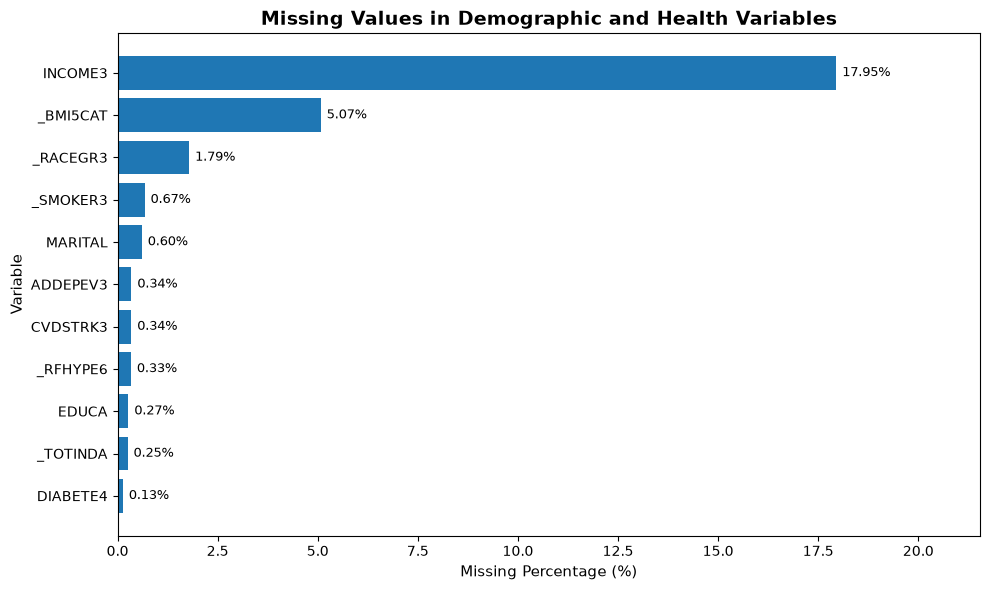

In [11]:
import matplotlib.pyplot as plt

# Original variables with missing values
missing_vars = [
    "INCOME3",
    "_BMI5CAT",
    "_RACEGR3",
    "_SMOKER3",
    "MARITAL",
    "ADDEPEV3",
    "CVDSTRK3",
    "_RFHYPE6",
    "EDUCA",
    "_TOTINDA",
    "DIABETE4"
]

# Calculate missing counts and percentages
missing_summary = pd.DataFrame({
    "Variable": missing_vars,
    "Missing_Count": [
        final_df[col].isna().sum() for col in missing_vars
    ],
    "Missing_Percentage": [
        final_df[col].isna().mean() * 100 for col in missing_vars
    ]
})

# Sort by missing percentage
missing_summary = missing_summary.sort_values(
    by="Missing_Percentage",
    ascending=False
)

# Display the complete missing value table
display(missing_summary.round(2))

# Plot horizontal bar chart
plot_data = missing_summary.sort_values(
    by="Missing_Percentage",
    ascending=True
)

plt.figure(figsize=(10, 6))

bars = plt.barh(
    plot_data["Variable"],
    plot_data["Missing_Percentage"]
)

plt.xlabel("Missing Percentage (%)", fontsize=11)
plt.ylabel("Variable", fontsize=11)

plt.title(
    "Missing Values in Demographic and Health Variables",
    fontsize=14,
    fontweight="bold"
)

# Add percentage labels
for bar in bars:
    width = bar.get_width()

    plt.text(
        width + 0.15,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.2f}%",
        va="center",
        fontsize=9
    )

plt.xlim(
    0,
    plot_data["Missing_Percentage"].max() * 1.2
)

plt.tight_layout()

# Save high-resolution figure
plt.savefig(
    "Figure2_Missing_Values.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [12]:
import pandas as pd

quality_checks = pd.DataFrame({
    "Quality Check": [
        "Required variables",
        "Age restriction",
        "SCD coding",
        "ACE item coding",
        "ACE score calculation",
        "ACE score range",
        "Missing SCD values",
        "Missing ACE scores",
        "Duplicate rows",
        "Survey design variables",
        "Missing survey design values"
    ],

    "Result": [
        "All selected variables available",
        "All respondents aged 45 or above",
        "Only 0 and 1",
        "All 11 items contain only 0 and 1",
        "Consistent with the sum of 11 ACE items",
        "0–11",
        str(final_df["SCD"].isna().sum()),
        str(final_df["ACE_score_11"].isna().sum()),
        str(final_df.duplicated().sum()),
        "All three variables retained",
        str(final_df[
            ["_LLCPWT", "_STSTR", "_PSU"]
        ].isna().sum().sum())
    ]
})

display(quality_checks)

,Quality Check,Result
0,Required variables,All selected variables available
1,Age restriction,All respondents aged 45 or above
2,SCD coding,Only 0 and 1
3,ACE item coding,All 11 items contain only 0 and 1
4,ACE score calculation,Consistent with the sum of 11 ACE items
5,ACE score range,0–11
6,Missing SCD values,0
7,Missing ACE scores,0
8,Duplicate rows,0
9,Survey design variables,All three variables retained


Feature Selection and Engineering

In [13]:

# ==========================================
# Step 1. Define Candidate Features
# ==========================================

# 1. Target variable
target = "SCD"

# 2. Demographic features
demographic_features = [
    "SEXVAR",
    "_AGE80",
    "_RACEGR3",
    "_STATE"
]

# 3. Socioeconomic features
socioeconomic_features = [
    "EDUCA",
    "INCOME3",
    "MARITAL"
]

# 4. Health features
health_features = [
    "_BMI5CAT",
    "DIABETE4",
    "Depression_bin",
    "Stroke_bin",
    "HighBP_bin"
]

# 5. Health behavior features
behavior_features = [
    "_SMOKER3",
    "PhysicalActivity_bin"
]

# 6. ACE individual features
ace_item_features = [
    "ACEDEPRS_bin",
    "ACEDRINK_bin",
    "ACEDRUGS_bin",
    "ACEPRISN_bin",
    "ACEDIVRC_bin",
    "ACEPUNCH_bin",
    "ACEHURT1_bin",
    "ACESWEAR_bin",
    "ACETOUCH_bin",
    "ACETTHEM_bin",
    "ACEHVSEX_bin"
]

# 7. ACE cumulative score
ace_score_features = ["ACE_score_11"]

# ==========================================
# Step 2. Construct Feature Sets
# ==========================================

# Baseline model: without ACE
base_features = (
    demographic_features +
    socioeconomic_features +
    health_features +
    behavior_features
)

# Model with 11 individual ACE items
features_with_ace = base_features + ace_item_features

# ==========================================
# Step 3. Check Feature Availability
# ==========================================

feature_sets = {
    "Without ACE": base_features,
    "With 11 ACE Items": features_with_ace
}

for name, features in feature_sets.items():

    missing = [
        col for col in features
        if col not in final_df.columns
    ]

    print(f"\n{name}")
    print("Number of features:", len(features))
    print("Missing variables:", missing)

    if len(missing) == 0:
        print("All features are available!")

# ==========================================
# Step 4. Display Feature Groups
# ==========================================

feature_groups = {
    "Demographic": demographic_features,
    "Socioeconomic": socioeconomic_features,
    "Health": health_features,
    "Health Behavior": behavior_features,
    "ACE Items": ace_item_features,
    "ACE Score": ace_score_features
}

for group, features in feature_groups.items():
    print(f"\n{group}: {len(features)} variables")
    print(features)

print("\nTarget variable:", target)
print("Dataset shape:", final_df.shape)



Without ACE
Number of features: 14
Missing variables: []
All features are available!

With 11 ACE Items
Number of features: 25
Missing variables: []
All features are available!

Demographic: 4 variables
['SEXVAR', '_AGE80', '_RACEGR3', '_STATE']

Socioeconomic: 3 variables
['EDUCA', 'INCOME3', 'MARITAL']

Health: 5 variables
['_BMI5CAT', 'DIABETE4', 'Depression_bin', 'Stroke_bin', 'HighBP_bin']

Health Behavior: 2 variables
['_SMOKER3', 'PhysicalActivity_bin']

ACE Items: 11 variables
['ACEDEPRS_bin', 'ACEDRINK_bin', 'ACEDRUGS_bin', 'ACEPRISN_bin', 'ACEDIVRC_bin', 'ACEPUNCH_bin', 'ACEHURT1_bin', 'ACESWEAR_bin', 'ACETOUCH_bin', 'ACETTHEM_bin', 'ACEHVSEX_bin']

ACE Score: 1 variables
['ACE_score_11']

Target variable: SCD
Dataset shape: (35754, 45)


In [14]:

# ==========================================
# Step 2. Inspect Feature Types and Values
# ==========================================

check_vars = (
    [target]
    + base_features
    + ace_item_features
)

inspection = []

for col in check_vars:

    s = final_df[col]
    unique_values = s.dropna().unique()

    inspection.append({
        "Variable": col,
        "Data_Type": str(s.dtype),
        "Missing_Count": s.isna().sum(),
        "Missing_Percent": round(s.isna().mean() * 100, 2),
        "Unique_Count": s.nunique(),
        "Example_Values": list(unique_values[:12])
    })

feature_inspection = pd.DataFrame(inspection)

display(feature_inspection)


,Variable,Data_Type,Missing_Count,Missing_Percent,Unique_Count,Example_Values
0,SCD,float64,0,0.00,2,"[0.0, 1.0]"
1,SEXVAR,float64,0,0.00,2,"[2.0, 1.0]"
2,_AGE80,float64,0,0.00,36,"[52.0, 67.0, 79.0, 66.0, 77.0, 74.0, 70.0, 69...."
3,_RACEGR3,float64,639,1.79,5,"[1.0, 2.0, 4.0, 3.0, 5.0]"
4,_STATE,float64,0,0.00,10,"[10.0, 12.0, 13.0, 29.0, 32.0, 34.0, 41.0, 44...."
5,EDUCA,float64,96,0.27,6,"[6.0, 4.0, 5.0, 3.0, 2.0, 1.0]"
6,INCOME3,float64,6418,17.95,11,"[8.0, 7.0, 4.0, 6.0, 5.0, 1.0, 9.0, 3.0, 11.0,..."
7,MARITAL,float64,216,0.60,6,"[6.0, 1.0, 2.0, 3.0, 4.0, 5.0]"
8,_BMI5CAT,float64,1814,5.07,4,"[3.0, 4.0, 2.0, 1.0]"
9,DIABETE4,float64,47,0.13,4,"[3.0, 1.0, 4.0, 2.0]"


In [15]:
# Inspect categorical variable frequencies

categorical_vars = [
    "SEXVAR",
    "_RACEGR3",
    "_STATE",
    "EDUCA",
    "INCOME3",
    "MARITAL",
    "_BMI5CAT",
    "DIABETE4",
    "_SMOKER3"
]

for col in categorical_vars:

    print("\n" + "=" * 45)
    print(f"Variable: {col}")
    print(final_df[col].value_counts(dropna=False).sort_index())



Variable: SEXVAR
SEXVAR
1.0    15627
2.0    20127
Name: count, dtype: int64

Variable: _RACEGR3
_RACEGR3
1.0    28574
2.0     3340
3.0      954
4.0      596
5.0     1651
NaN      639
Name: count, dtype: int64

Variable: _STATE
_STATE
10.0    2354
12.0    7010
13.0    4259
29.0    3610
32.0    1323
34.0    4668
41.0    2927
44.0    3331
47.0    2779
51.0    3493
Name: count, dtype: int64

Variable: EDUCA
EDUCA
1.0       28
2.0      572
3.0     1261
4.0     8387
5.0     9312
6.0    16098
NaN       96
Name: count, dtype: int64

Variable: INCOME3
INCOME3
1.0      603
2.0      874
3.0     1124
4.0     1671
5.0     3287
6.0     3865
7.0     4878
8.0     4277
9.0     4381
10.0    2075
11.0    2301
NaN     6418
Name: count, dtype: int64

Variable: MARITAL
MARITAL
1.0    20022
2.0     5477
3.0     5965
4.0      588
5.0     2735
6.0      751
NaN      216
Name: count, dtype: int64

Variable: _BMI5CAT
_BMI5CAT
1.0      481
2.0     9579
3.0    12536
4.0    11344
NaN     1814
Name: count, dtype: in

In [16]:

# ==========================================
# Step 3. Create Feature Dictionary
# ==========================================

feature_dictionary = [

    # Target
    {
        "Variable": "SCD",
        "Feature_Group": "Target",
        "Description": "Subjective Cognitive Decline status",
        "Variable_Type": "Binary",
        "Encoding_Method": "0/1 (Target)",
        "Missing_Percent": 0.00
    },

    # Demographic
    {
        "Variable": "SEXVAR",
        "Feature_Group": "Demographic",
        "Description": "Sex",
        "Variable_Type": "Binary categorical",
        "Encoding_Method": "Binary encoding: 0 = Male, 1 = Female",
        "Missing_Percent": 0.00
    },
    {
        "Variable": "_AGE80",
        "Feature_Group": "Demographic",
        "Description": "Age",
        "Variable_Type": "Numerical",
        "Encoding_Method": "Standardization for Logistic Regression",
        "Missing_Percent": 0.00
    },
    {
        "Variable": "_RACEGR3",
        "Feature_Group": "Demographic",
        "Description": "Race and ethnicity",
        "Variable_Type": "Nominal categorical",
        "Encoding_Method": "One-Hot Encoding",
        "Missing_Percent": 1.79
    },
    {
        "Variable": "_STATE",
        "Feature_Group": "Demographic",
        "Description": "State of residence",
        "Variable_Type": "Nominal categorical",
        "Encoding_Method": "One-Hot Encoding",
        "Missing_Percent": 0.00
    },

    # Socioeconomic
    {
        "Variable": "EDUCA",
        "Feature_Group": "Socioeconomic",
        "Description": "Education level",
        "Variable_Type": "Ordinal categorical",
        "Encoding_Method": "One-Hot Encoding",
        "Missing_Percent": 0.27
    },
    {
        "Variable": "INCOME3",
        "Feature_Group": "Socioeconomic",
        "Description": "Household income category",
        "Variable_Type": "Ordinal categorical",
        "Encoding_Method": "One-Hot Encoding",
        "Missing_Percent": 17.95
    },
    {
        "Variable": "MARITAL",
        "Feature_Group": "Socioeconomic",
        "Description": "Marital status",
        "Variable_Type": "Nominal categorical",
        "Encoding_Method": "One-Hot Encoding",
        "Missing_Percent": 0.60
    },

    # Health
    {
        "Variable": "_BMI5CAT",
        "Feature_Group": "Health",
        "Description": "BMI category",
        "Variable_Type": "Ordinal categorical",
        "Encoding_Method": "One-Hot Encoding",
        "Missing_Percent": 5.07
    },
    {
        "Variable": "DIABETE4",
        "Feature_Group": "Health",
        "Description": "Diabetes status",
        "Variable_Type": "Categorical",
        "Encoding_Method": "One-Hot Encoding",
        "Missing_Percent": 0.13
    },
    {
        "Variable": "Depression_bin",
        "Feature_Group": "Health",
        "Description": "History of depressive disorder",
        "Variable_Type": "Binary",
        "Encoding_Method": "Keep 0/1",
        "Missing_Percent": 0.34
    },
    {
        "Variable": "Stroke_bin",
        "Feature_Group": "Health",
        "Description": "History of stroke",
        "Variable_Type": "Binary",
        "Encoding_Method": "Keep 0/1",
        "Missing_Percent": 0.34
    },
    {
        "Variable": "HighBP_bin",
        "Feature_Group": "Health",
        "Description": "High blood pressure",
        "Variable_Type": "Binary",
        "Encoding_Method": "Keep 0/1",
        "Missing_Percent": 0.33
    },

    # Health Behavior
    {
        "Variable": "_SMOKER3",
        "Feature_Group": "Health Behavior",
        "Description": "Smoking status",
        "Variable_Type": "Categorical",
        "Encoding_Method": "One-Hot Encoding",
        "Missing_Percent": 0.67
    },
    {
        "Variable": "PhysicalActivity_bin",
        "Feature_Group": "Health Behavior",
        "Description": "Physical activity status",
        "Variable_Type": "Binary",
        "Encoding_Method": "Keep 0/1",
        "Missing_Percent": 0.25
    }
]

# Add 11 ACE variables
ace_descriptions = {
    "ACEDEPRS_bin": "Household member with depression or mental illness",
    "ACEDRINK_bin": "Household member with alcohol problems",
    "ACEDRUGS_bin": "Household member with drug problems",
    "ACEPRISN_bin": "Household member incarcerated",
    "ACEDIVRC_bin": "Parental divorce or separation",
    "ACEPUNCH_bin": "Household violence",
    "ACEHURT1_bin": "Physical abuse",
    "ACESWEAR_bin": "Verbal abuse",
    "ACETOUCH_bin": "Unwanted sexual touching",
    "ACETTHEM_bin": "Being forced to touch someone sexually",
    "ACEHVSEX_bin": "Being forced to have sex"
}

for variable, description in ace_descriptions.items():

    feature_dictionary.append({
        "Variable": variable,
        "Feature_Group": "ACE",
        "Description": description,
        "Variable_Type": "Binary",
        "Encoding_Method": "Keep 0/1",
        "Missing_Percent": 0.00
    })

# Convert to DataFrame
feature_dictionary_df = pd.DataFrame(feature_dictionary)

# Display
display(feature_dictionary_df)

# Save
feature_dictionary_df.to_csv(
    "Feature_Dictionary.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Feature Dictionary saved successfully!")
print("Total predictors:", len(feature_dictionary_df) - 1)


,Variable,Feature_Group,Description,Variable_Type,Encoding_Method,Missing_Percent
0,SCD,Target,Subjective Cognitive Decline status,Binary,0/1 (Target),0.00
1,SEXVAR,Demographic,Sex,Binary categorical,"Binary encoding: 0 = Male, 1 = Female",0.00
2,_AGE80,Demographic,Age,Numerical,Standardization for Logistic Regression,0.00
3,_RACEGR3,Demographic,Race and ethnicity,Nominal categorical,One-Hot Encoding,1.79
4,_STATE,Demographic,State of residence,Nominal categorical,One-Hot Encoding,0.00
5,EDUCA,Socioeconomic,Education level,Ordinal categorical,One-Hot Encoding,0.27
6,INCOME3,Socioeconomic,Household income category,Ordinal categorical,One-Hot Encoding,17.95
7,MARITAL,Socioeconomic,Marital status,Nominal categorical,One-Hot Encoding,0.60
8,_BMI5CAT,Health,BMI category,Ordinal categorical,One-Hot Encoding,5.07
9,DIABETE4,Health,Diabetes status,Categorical,One-Hot Encoding,0.13


Feature Dictionary saved successfully!
Total predictors: 25


In [17]:

# ==========================================
# Step 4. Create Machine Learning Dataset
# ==========================================

# Combine all candidate predictors
all_features = base_features + ace_item_features

# Extract target and predictors
model_data = final_df[
    [target] + all_features
].copy()
# Recode SEXVAR before splitting and exporting the modeling dataset
model_data["SEXVAR"] = model_data["SEXVAR"].map({1: 0, 2: 1})

# Check dataset
print("Machine Learning Dataset Shape:", model_data.shape)

print("\nMissing values:")
display(
    model_data.isnull().sum().sort_values(
        ascending=False
    )
)

print("\nFirst five rows:")
display(model_data.head())


Machine Learning Dataset Shape: (35754, 26)

Missing values:


INCOME3                 6418
_BMI5CAT                1814
_RACEGR3                 639
_SMOKER3                 241
MARITAL                  216
Depression_bin           123
Stroke_bin               122
HighBP_bin               119
EDUCA                     96
PhysicalActivity_bin      89
DIABETE4                  47
_STATE                     0
SCD                        0
SEXVAR                     0
_AGE80                     0
ACEDEPRS_bin               0
ACEDRINK_bin               0
ACEDRUGS_bin               0
ACEPRISN_bin               0
ACEDIVRC_bin               0
ACEPUNCH_bin               0
ACEHURT1_bin               0
ACESWEAR_bin               0
ACETOUCH_bin               0
ACETTHEM_bin               0
ACEHVSEX_bin               0
dtype: int64


First five rows:


,SCD,SEXVAR,_AGE80,_RACEGR3,_STATE,EDUCA,INCOME3,MARITAL,_BMI5CAT,DIABETE4,...,ACEDRINK_bin,ACEDRUGS_bin,ACEPRISN_bin,ACEDIVRC_bin,ACEPUNCH_bin,ACEHURT1_bin,ACESWEAR_bin,ACETOUCH_bin,ACETTHEM_bin,ACEHVSEX_bin
57534,0.0,1,52.0,1.0,10.0,6.0,8.0,6.0,3.0,3.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
57535,0.0,0,67.0,1.0,10.0,4.0,7.0,1.0,4.0,3.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
57536,0.0,1,79.0,2.0,10.0,4.0,4.0,2.0,2.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
57537,0.0,1,66.0,1.0,10.0,4.0,6.0,2.0,4.0,3.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
57539,0.0,1,77.0,1.0,10.0,6.0,6.0,3.0,4.0,3.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [18]:

# ==========================================
# Step 5. Stratified Train-Test Split
# ==========================================

from sklearn.model_selection import train_test_split
import numpy as np

# Create row indices
indices = np.arange(len(model_data))

# Stratified split: 80% training, 20% testing
train_idx, test_idx = train_test_split(
    indices,
    test_size=0.2,
    random_state=42,
    stratify=model_data[target]
)

# Record split assignment
split_labels = pd.Series(
    "train",
    index=model_data.index
)

split_labels.iloc[test_idx] = "test"

model_data["Dataset_Split"] = split_labels

# Check sample sizes
print("Training samples:", len(train_idx))
print("Testing samples:", len(test_idx))

# Check class distribution
print("\nClass counts:")
display(
    pd.crosstab(
        model_data["Dataset_Split"],
        model_data[target],
        margins=True
    )
)

print("\nClass percentages:")
display(
    pd.crosstab(
        model_data["Dataset_Split"],
        model_data[target],
        normalize="index"
    ) * 100
)


Training samples: 28603
Testing samples: 7151

Class counts:


SCD,0.0,1.0,All
Dataset_Split,,,
test,5928,1223,7151
train,23713,4890,28603
All,29641,6113,35754



Class percentages:


SCD,0.0,1.0
Dataset_Split,,
test,82.897497,17.102503
train,82.903891,17.096109


In [19]:

# ==========================================
# Step 6. Save Machine Learning Dataset
# ==========================================

model_data.to_csv(
    "BRFSS_2023_ML_Feature_Dataset.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Machine Learning Dataset saved successfully!")

print("Final shape:", model_data.shape)

print("\nSplit distribution:")
print(model_data["Dataset_Split"].value_counts())


Machine Learning Dataset saved successfully!
Final shape: (35754, 27)

Split distribution:
Dataset_Split
train    28603
test      7151
Name: count, dtype: int64


In [20]:

# ==========================================
# Step 7. Define Preprocessing Components
# ==========================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numerical features
numeric_features = [
    "_AGE80"
]

# Categorical features: One-Hot Encoding
categorical_features = [
    "_RACEGR3",
    "_STATE",
    "EDUCA",
    "INCOME3",
    "MARITAL",
    "_BMI5CAT",
    "DIABETE4",
    "_SMOKER3"
]

# Binary features: Keep as 0/1
binary_features = [
    "SEXVAR",
    "Depression_bin",
    "Stroke_bin",
    "HighBP_bin",
    "PhysicalActivity_bin"
]

# ACE features
ace_binary_features = ace_item_features

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Binary features:", len(binary_features))
print("ACE features:", len(ace_binary_features))

print("\nTotal base features:",
      len(numeric_features) +
      len(categorical_features) +
      len(binary_features))

print("Total features with ACE:",
      len(numeric_features) +
      len(categorical_features) +
      len(binary_features) +
      len(ace_binary_features))

Numerical features: 1
Categorical features: 8
Binary features: 5
ACE features: 11

Total base features: 14
Total features with ACE: 25


In [21]:

# ==========================================
# Step 8. Create Preprocessing Function
# ==========================================

def create_preprocessor(features, scale_numeric=False):

    # Select features according to their types
    num_cols = [
        col for col in numeric_features
        if col in features
    ]

    cat_cols = [
        col for col in categorical_features
        if col in features
    ]

    bin_cols = [
        col for col in (binary_features + ace_binary_features)
        if col in features
    ]

    # Check whether all selected features are assigned
    assert (
        len(num_cols) + len(cat_cols) + len(bin_cols)
        == len(features)
    ), "Some features have not been assigned!"

    # Numerical preprocessing
    if scale_numeric:
        numerical_transformer = Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ])
    else:
        numerical_transformer = Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="median"))
        ])

    # Categorical preprocessing
    categorical_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            drop="first"
        ))
    ])

    # Binary preprocessing
    binary_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent"))
    ])

    # Combine all transformations
    preprocessor = ColumnTransformer(
        transformers=[
            ("num", numerical_transformer, num_cols),
            ("cat", categorical_transformer, cat_cols),
            ("bin", binary_transformer, bin_cols)
        ],
        remainder="drop"
    )

    return preprocessor

In [22]:

# ==========================================
# Step 9. Build Four Preprocessing Pipelines
# ==========================================

# 1. Without ACE - Logistic Regression
preprocessor_lr_base = create_preprocessor(
    base_features,
    scale_numeric=True
)

# 2. Without ACE - Tree-based models
preprocessor_tree_base = create_preprocessor(
    base_features,
    scale_numeric=False
)

# 3. With ACE - Logistic Regression
preprocessor_lr_ace = create_preprocessor(
    features_with_ace,
    scale_numeric=True
)

# 4. With ACE - Tree-based models
preprocessor_tree_ace = create_preprocessor(
    features_with_ace,
    scale_numeric=False
)

print("Four preprocessing pipelines created successfully!")

print("\nWithout ACE features:", len(base_features))
print("With ACE features:", len(features_with_ace))

Four preprocessing pipelines created successfully!

Without ACE features: 14
With ACE features: 25


In [23]:

# ==========================================
# Step 10. Prepare Training and Testing Data
# ==========================================

# Identify training and testing observations
train_mask = model_data["Dataset_Split"] == "train"
test_mask = model_data["Dataset_Split"] == "test"

# Target variable
y_train = model_data.loc[train_mask, target].astype(int)
y_test = model_data.loc[test_mask, target].astype(int)

# Feature set 1: Without ACE
X_train_base = model_data.loc[
    train_mask, base_features
].copy()

X_test_base = model_data.loc[
    test_mask, base_features
].copy()

# Feature set 2: With ACE
X_train_ace = model_data.loc[
    train_mask, features_with_ace
].copy()

X_test_ace = model_data.loc[
    test_mask, features_with_ace
].copy()

# Check dataset sizes
print("Without ACE:")
print("X_train:", X_train_base.shape)
print("X_test:", X_test_base.shape)

print("\nWith ACE:")
print("X_train:", X_train_ace.shape)
print("X_test:", X_test_ace.shape)

print("\nTarget sizes:")
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

# Check SEXVAR recoding
print("\nSEXVAR values after recoding:")
print(X_train_base["SEXVAR"].value_counts())

# Check target values
print("\nTarget classes:")
print(y_train.value_counts())

Without ACE:
X_train: (28603, 14)
X_test: (7151, 14)

With ACE:
X_train: (28603, 25)
X_test: (7151, 25)

Target sizes:
y_train: (28603,)
y_test: (7151,)

SEXVAR values after recoding:
SEXVAR
1    16088
0    12515
Name: count, dtype: int64

Target classes:
SCD
0    23713
1     4890
Name: count, dtype: int64


In [24]:

# ==========================================
# Step 11. Fit and Transform Data
# ==========================================

from scipy import sparse
import numpy as np

# Store four preprocessing configurations
preprocessing_configs = {
    "LR - Without ACE": (
        preprocessor_lr_base,
        X_train_base,
        X_test_base
    ),
    "Tree - Without ACE": (
        preprocessor_tree_base,
        X_train_base,
        X_test_base
    ),
    "LR - With ACE": (
        preprocessor_lr_ace,
        X_train_ace,
        X_test_ace
    ),
    "Tree - With ACE": (
        preprocessor_tree_ace,
        X_train_ace,
        X_test_ace
    )
}

# Store transformed datasets
processed_results = {}

def count_missing_values(X):
    if sparse.issparse(X):
        return int(np.isnan(X.data).sum())
    return int(np.isnan(X).sum())


for name, (preprocessor, X_train, X_test) in preprocessing_configs.items():

    # Fit on training data only
    X_train_processed = preprocessor.fit_transform(X_train)

    # Transform testing data using training parameters
    X_test_processed = preprocessor.transform(X_test)

    # Save results for inspection
    processed_results[name] = {
        "X_train": X_train_processed,
        "X_test": X_test_processed,
        "feature_names": preprocessor.get_feature_names_out()
    }

    print("\n" + "=" * 50)
    print(name)

    print("Training shape:", X_train_processed.shape)
    print("Testing shape:", X_test_processed.shape)

    print("Number of output features:",
          len(preprocessor.get_feature_names_out()))

    print("Missing values in training:",
          count_missing_values(X_train_processed))

    print("Missing values in testing:",
          count_missing_values(X_test_processed))

print("\nAll four preprocessing configurations completed!")



LR - Without ACE
Training shape: (28603, 48)
Testing shape: (7151, 48)
Number of output features: 48
Missing values in training: 0
Missing values in testing: 0

Tree - Without ACE
Training shape: (28603, 48)
Testing shape: (7151, 48)
Number of output features: 48
Missing values in training: 0
Missing values in testing: 0

LR - With ACE
Training shape: (28603, 59)
Testing shape: (7151, 59)
Number of output features: 59
Missing values in training: 0
Missing values in testing: 0

Tree - With ACE
Training shape: (28603, 59)
Testing shape: (7151, 59)
Number of output features: 59
Missing values in training: 0
Missing values in testing: 0

All four preprocessing configurations completed!


Exploratory Data Analysis (EDA)
1. Target Variable Distribution

,SCD Status,Count,Percentage (%)
0,No SCD,29641,82.9
1,SCD,6113,17.1


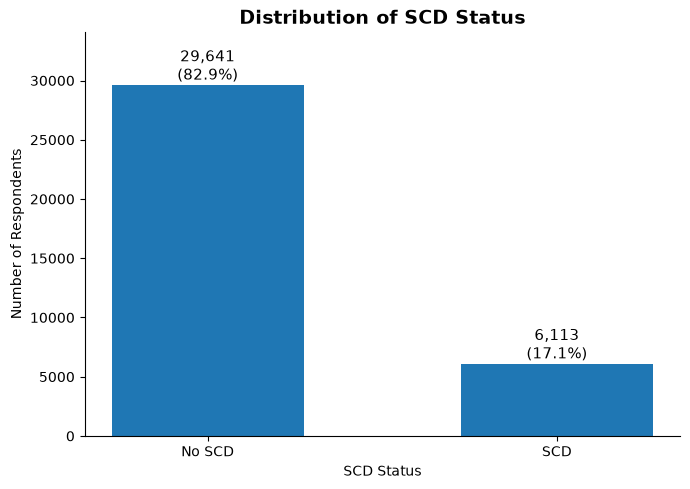

In [25]:

# ==========================================
# EDA 1. Target Variable Distribution
# ==========================================

import matplotlib.pyplot as plt
import pandas as pd

# Calculate counts and percentages
scd_counts = model_data["SCD"].value_counts().sort_index()

scd_labels = ["No SCD", "SCD"]
counts = scd_counts.values
percentages = counts / counts.sum() * 100

# Create a summary table
scd_summary = pd.DataFrame({
    "SCD Status": scd_labels,
    "Count": counts,
    "Percentage (%)": percentages.round(2)
})

display(scd_summary)

# Plot
fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    scd_labels,
    counts,
    width=0.55
)

# Add count and percentage labels
for bar, count, pct in zip(bars, counts, percentages):

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,}\n({pct:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=11
    )

ax.set_title(
    "Distribution of SCD Status",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("SCD Status")
ax.set_ylabel("Number of Respondents")

ax.set_ylim(0, max(counts) * 1.15)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


Age Summary Statistics:


count    35754.000000
mean        65.820719
std         10.379495
min         45.000000
25%         58.000000
50%         67.000000
75%         75.000000
max         80.000000
Name: _AGE80, dtype: float64

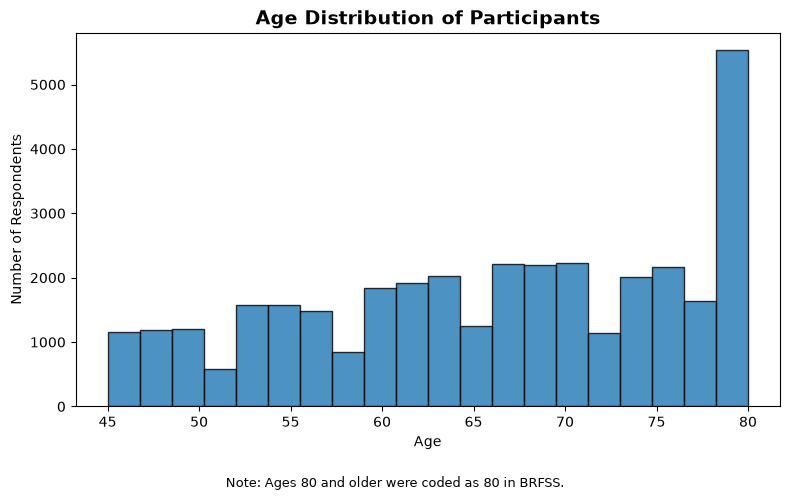

In [26]:
# ==========================================
# EDA 2A. Age Distribution
# ==========================================

import matplotlib.pyplot as plt

age = model_data["_AGE80"].dropna()

# Summary statistics
print("Age Summary Statistics:")
display(age.describe())

# Plot histogram
plt.figure(figsize=(8, 5))

plt.hist(
    age,
    bins=20,
    edgecolor="black",
    alpha=0.8
)

plt.title("Age Distribution of Participants",
          fontsize=14, fontweight="bold")

plt.xlabel("Age")
plt.ylabel("Number of Respondents")

plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.gcf().text(
    0.5, 0.015,
    "Note: Ages 80 and older were coded as 80 in BRFSS.",
    ha="center", fontsize=9
)
plt.show()


,No SCD,SCD
count,23713.000000,4890.000000
mean,65.667355,66.521472
std,10.334291,10.514230
min,45.000000,45.000000
25%,58.000000,58.000000
50%,66.000000,67.000000
75%,75.000000,76.000000
max,80.000000,80.000000


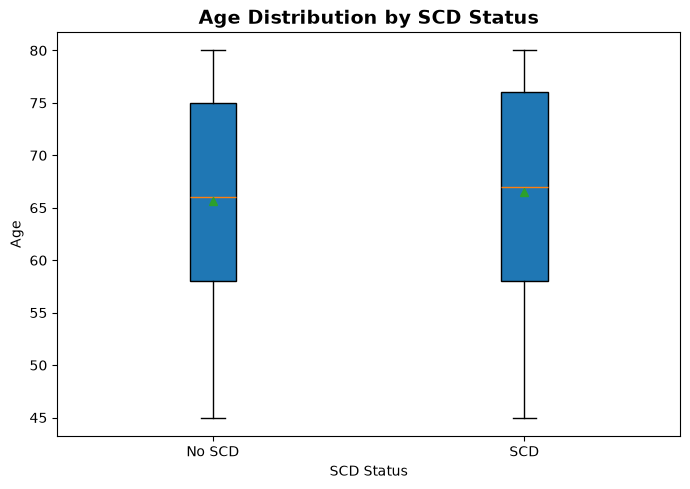

In [27]:
# ==========================================
# EDA 2B. Age Distribution by SCD Status
# ==========================================

age_eda = model_data.loc[model_data["Dataset_Split"].eq("train")]

age_no_scd = age_eda.loc[
    age_eda["SCD"] == 0, "_AGE80"
].dropna()

age_scd = age_eda.loc[
    age_eda["SCD"] == 1, "_AGE80"
].dropna()

# Summary comparison
age_comparison = pd.DataFrame({
    "No SCD": age_no_scd.describe(),
    "SCD": age_scd.describe()
})

display(age_comparison)

# Boxplot
fig, ax = plt.subplots(figsize=(7, 5))

ax.boxplot(
    [age_no_scd, age_scd],
    tick_labels=["No SCD", "SCD"],
    patch_artist=True,
    showmeans=True
)

ax.set_title(
    "Age Distribution by SCD Status",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("SCD Status")
ax.set_ylabel("Age")

plt.tight_layout()
plt.show()



Sex Distribution


,Category,Count,Percentage (%)
0,Female,20127,56.29
1,Male,15627,43.71


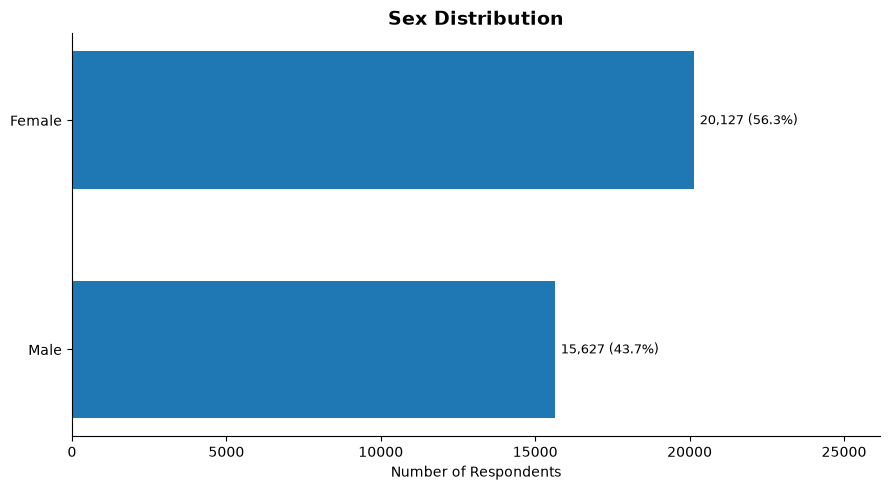


Race and Ethnicity Distribution


,Category,Count,Percentage (%)
0,"White, non-Hispanic",28574,79.92
1,"Black, non-Hispanic",3340,9.34
2,Hispanic,1651,4.62
3,"Other race, non-Hispanic",954,2.67
4,Missing,639,1.79
5,"Multiracial, non-Hispanic",596,1.67


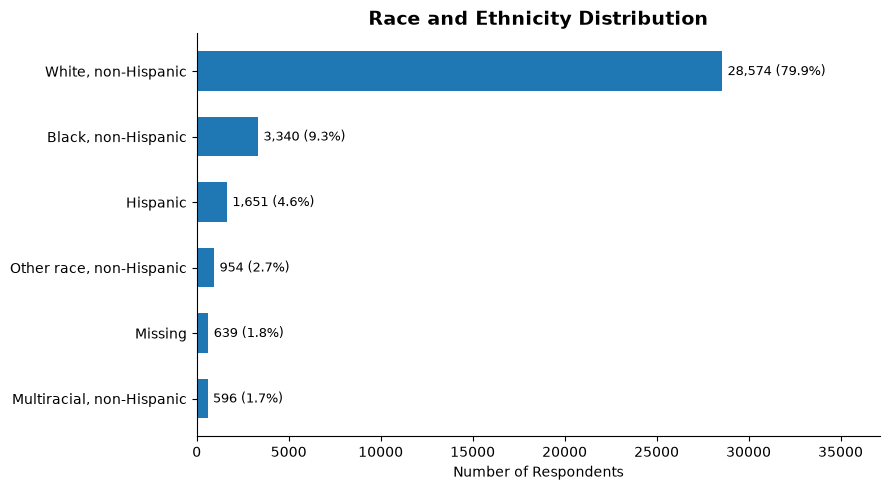


Sample Distribution Across States


,Category,Count,Percentage (%)
0,Florida,7010,19.61
1,New Jersey,4668,13.06
2,Georgia,4259,11.91
3,Missouri,3610,10.10
4,Virginia,3493,9.77
5,Rhode Island,3331,9.32
6,Oregon,2927,8.19
7,Tennessee,2779,7.77
8,Delaware,2354,6.58
9,Nevada,1323,3.70


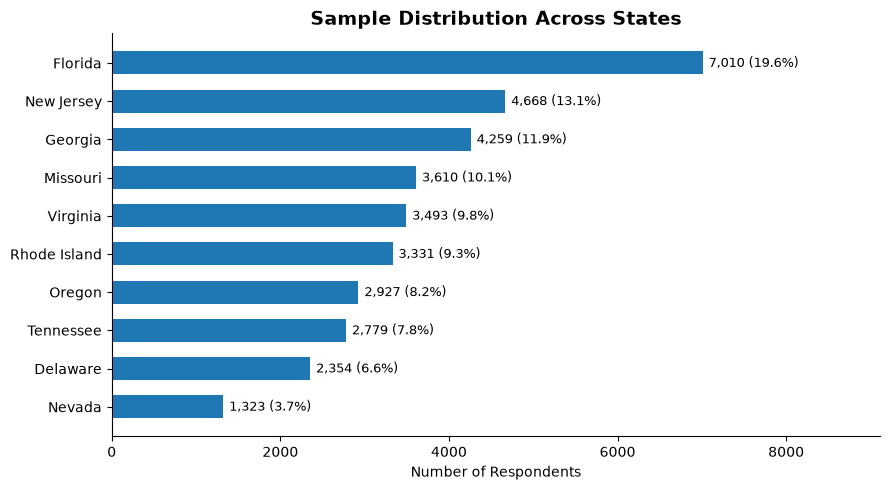

In [28]:
# ==========================================
# EDA 3. Demographic Feature Distribution
# ==========================================

import matplotlib.pyplot as plt
import pandas as pd

# Define category labels
demographic_mappings = {

    "SEXVAR": {
        0: "Male",
        1: "Female"
    },

    "_RACEGR3": {
        1.0: "White, non-Hispanic",
        2.0: "Black, non-Hispanic",
        3.0: "Other race, non-Hispanic",
        4.0: "Multiracial, non-Hispanic",
        5.0: "Hispanic"
    },

    "_STATE": {
        10.0: "Delaware",
        12.0: "Florida",
        13.0: "Georgia",
        29.0: "Missouri",
        32.0: "Nevada",
        34.0: "New Jersey",
        41.0: "Oregon",
        44.0: "Rhode Island",
        47.0: "Tennessee",
        51.0: "Virginia"
    }
}

# Chart titles
chart_titles = {
    "SEXVAR": "Sex Distribution",
    "_RACEGR3": "Race and Ethnicity Distribution",
    "_STATE": "Sample Distribution Across States"
}

# Generate three horizontal bar charts
for variable, mapping in demographic_mappings.items():

    # Convert codes into readable labels
    labels = (
        model_data[variable]
        .map(mapping)
        .fillna("Missing")
    )

    # Calculate counts and percentages
    summary = (
        labels.value_counts()
        .rename_axis("Category")
        .reset_index(name="Count")
    )

    summary["Percentage (%)"] = (
        summary["Count"] /
        summary["Count"].sum() * 100
    ).round(2)

    print("\n" + "=" * 50)
    print(chart_titles[variable])
    display(summary)

    # Sort for horizontal bar chart
    plot_data = summary.sort_values(
        "Count",
        ascending=True
    )

    # Plot
    fig, ax = plt.subplots(figsize=(9, 5))

    bars = ax.barh(
        plot_data["Category"],
        plot_data["Count"],
        height=0.6
    )

    # Add count and percentage labels
    for bar, count, pct in zip(
        bars,
        plot_data["Count"],
        plot_data["Percentage (%)"]
    ):

        ax.text(
            bar.get_width() + summary["Count"].max() * 0.01,
            bar.get_y() + bar.get_height() / 2,
            f"{count:,} ({pct:.1f}%)",
            va="center",
            fontsize=9
        )

    ax.set_title(
        chart_titles[variable],
        fontsize=14,
        fontweight="bold"
    )

    ax.set_xlabel("Number of Respondents")
    ax.set_ylabel("")

    ax.set_xlim(
        0,
        summary["Count"].max() * 1.3
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()
    plt.show()



Education Level Distribution


,Category,Count,Percentage (%)
0,No schooling / Kindergarten,28,0.08
1,Grades 1-8,572,1.60
2,Grades 9-11,1261,3.53
3,High school / GED,8387,23.46
4,Some college / Technical school,9312,26.04
5,College graduate,16098,45.02
6,Missing,96,0.27


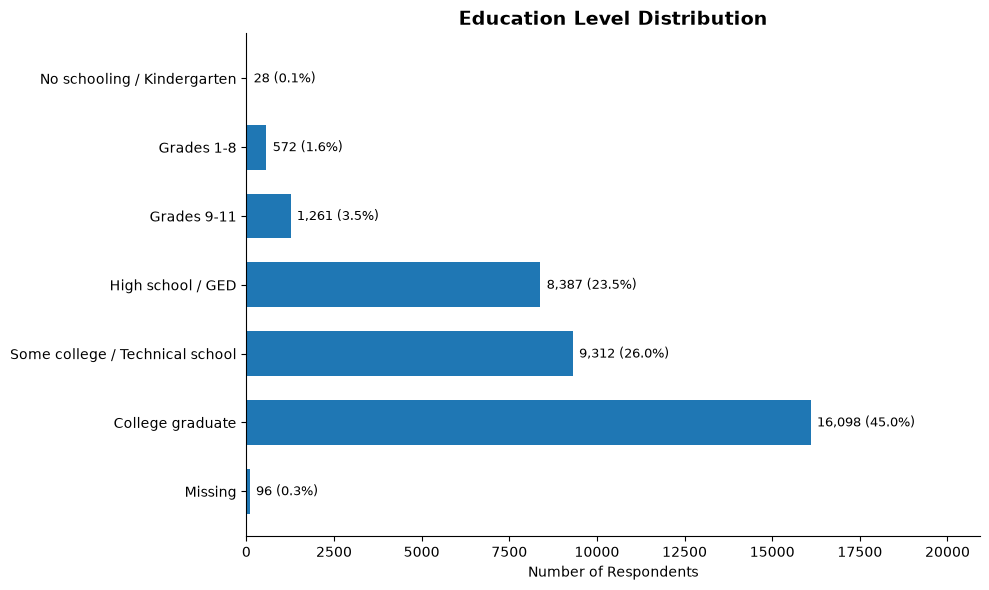


Household Income Distribution


,Category,Count,Percentage (%)
0,"< $10,000",603,1.69
1,"$10,000-$14,999",874,2.44
2,"$15,000-$19,999",1124,3.14
3,"$20,000-$24,999",1671,4.67
4,"$25,000-$34,999",3287,9.19
5,"$35,000-$49,999",3865,10.81
6,"$50,000-$74,999",4878,13.64
7,"$75,000-$99,999",4277,11.96
8,"$100,000-$149,999",4381,12.25
9,"$150,000-$199,999",2075,5.80


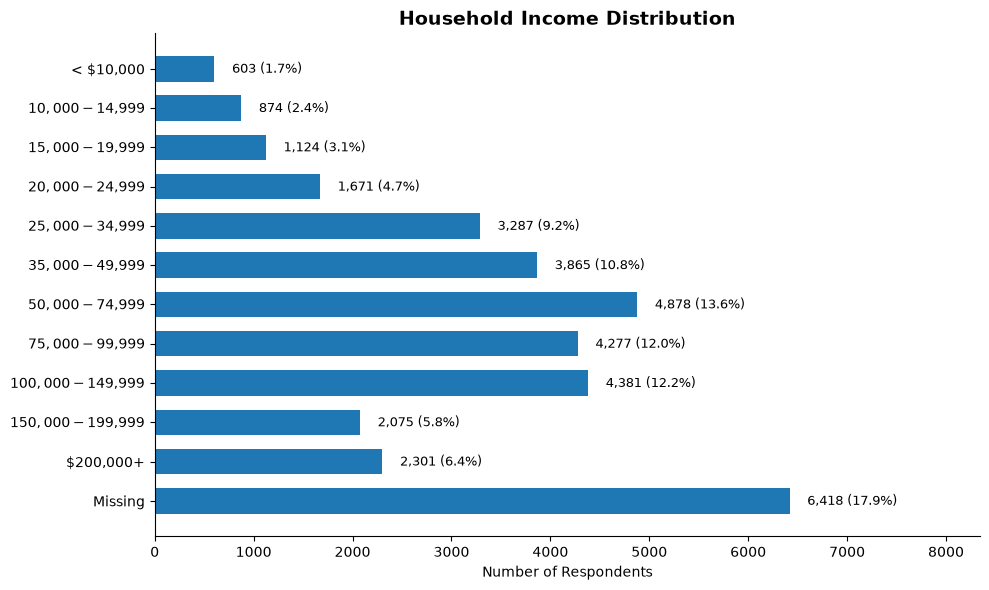


Marital Status Distribution


,Category,Count,Percentage (%)
0,Married,20022,56.00
1,Divorced,5477,15.32
2,Widowed,5965,16.68
3,Separated,588,1.64
4,Never married,2735,7.65
5,Unmarried couple,751,2.10
6,Missing,216,0.60


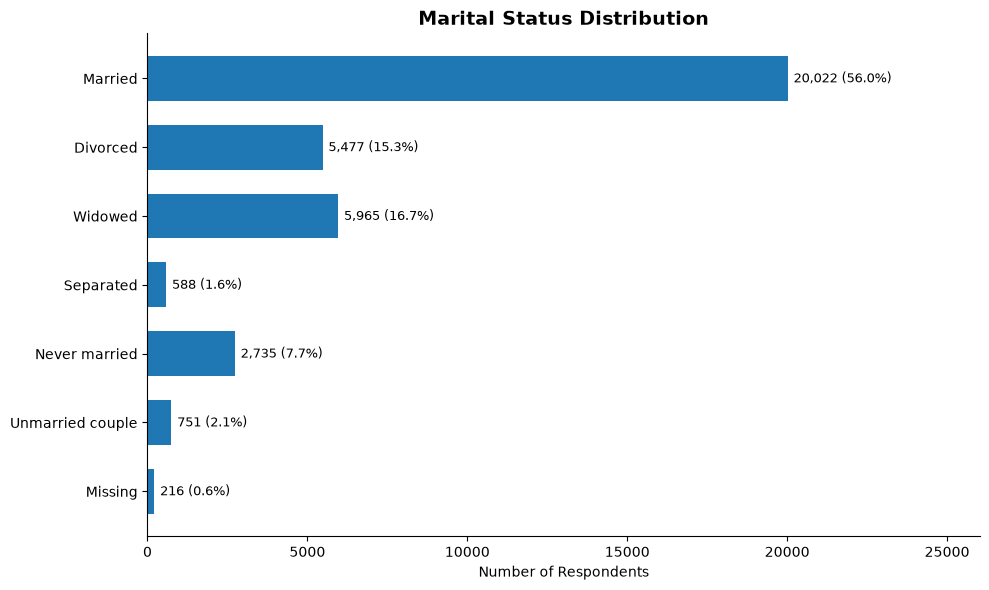

In [29]:

# ==========================================
# EDA 4. Socioeconomic Feature Distribution
# ==========================================

import matplotlib.pyplot as plt
import pandas as pd

socioeconomic_mappings = {

    "EDUCA": {
        1.0: "No schooling / Kindergarten",
        2.0: "Grades 1-8",
        3.0: "Grades 9-11",
        4.0: "High school / GED",
        5.0: "Some college / Technical school",
        6.0: "College graduate"
    },

    "INCOME3": {
        1.0: "< $10,000",
        2.0: "$10,000-$14,999",
        3.0: "$15,000-$19,999",
        4.0: "$20,000-$24,999",
        5.0: "$25,000-$34,999",
        6.0: "$35,000-$49,999",
        7.0: "$50,000-$74,999",
        8.0: "$75,000-$99,999",
        9.0: "$100,000-$149,999",
        10.0: "$150,000-$199,999",
        11.0: "$200,000+"
    },

    "MARITAL": {
        1.0: "Married",
        2.0: "Divorced",
        3.0: "Widowed",
        4.0: "Separated",
        5.0: "Never married",
        6.0: "Unmarried couple"
    }
}

# Keep the original category order
category_orders = {

    "EDUCA": [
        "No schooling / Kindergarten",
        "Grades 1-8",
        "Grades 9-11",
        "High school / GED",
        "Some college / Technical school",
        "College graduate",
        "Missing"
    ],

    "INCOME3": [
        "< $10,000",
        "$10,000-$14,999",
        "$15,000-$19,999",
        "$20,000-$24,999",
        "$25,000-$34,999",
        "$35,000-$49,999",
        "$50,000-$74,999",
        "$75,000-$99,999",
        "$100,000-$149,999",
        "$150,000-$199,999",
        "$200,000+",
        "Missing"
    ],

    "MARITAL": [
        "Married",
        "Divorced",
        "Widowed",
        "Separated",
        "Never married",
        "Unmarried couple",
        "Missing"
    ]
}

chart_titles = {
    "EDUCA": "Education Level Distribution",
    "INCOME3": "Household Income Distribution",
    "MARITAL": "Marital Status Distribution"
}

for variable, mapping in socioeconomic_mappings.items():

    # Convert original codes into readable categories
    labels = (
        model_data[variable]
        .map(mapping)
        .fillna("Missing")
    )

    # Count categories in the predefined order
    summary = (
        labels.value_counts()
        .reindex(category_orders[variable], fill_value=0)
        .rename_axis("Category")
        .reset_index(name="Count")
    )

    # Calculate percentages using the full sample
    summary["Percentage (%)"] = (
        summary["Count"] / len(model_data) * 100
    ).round(2)

    print("\n" + "=" * 50)
    print(chart_titles[variable])
    display(summary)

    # Plot horizontal bar chart
    plot_data = summary.iloc[::-1]

    fig, ax = plt.subplots(figsize=(10, 6))

    bars = ax.barh(
        plot_data["Category"],
        plot_data["Count"],
        height=0.65
    )

    # Add count and percentage labels
    for bar, count, pct in zip(
        bars,
        plot_data["Count"],
        plot_data["Percentage (%)"]
    ):

        ax.text(
            bar.get_width() + len(model_data) * 0.005,
            bar.get_y() + bar.get_height() / 2,
            f"{count:,} ({pct:.1f}%)",
            va="center",
            fontsize=9
        )

    ax.set_title(
        chart_titles[variable],
        fontsize=14,
        fontweight="bold"
    )

    ax.set_xlabel("Number of Respondents")
    ax.set_ylabel("")

    ax.set_xlim(
        0,
        max(summary["Count"].max() * 1.3, 1)
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()
    plt.show()



BMI Category Distribution


,Category,Count,Percentage (%)
0,Underweight,481,1.35
1,Normal weight,9579,26.79
2,Overweight,12536,35.06
3,Obese,11344,31.73
4,Missing,1814,5.07


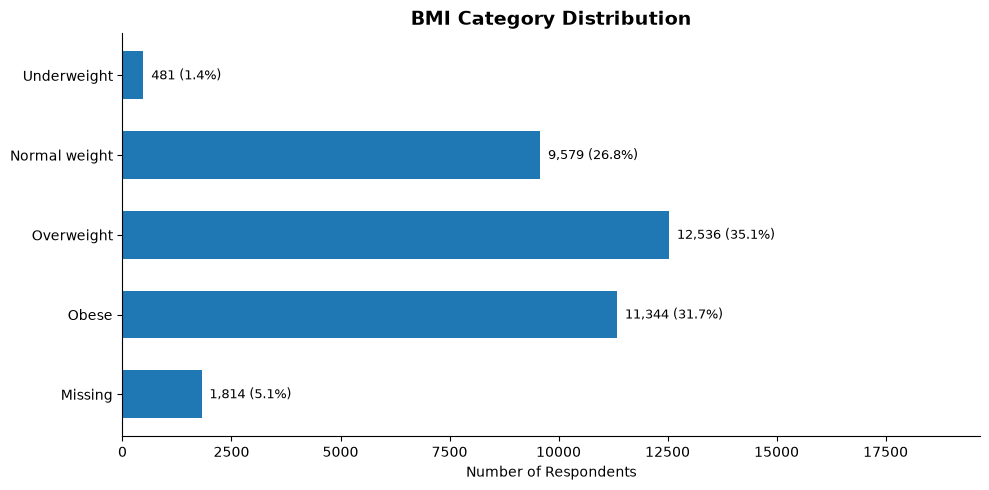


Diabetes Status Distribution


,Category,Count,Percentage (%)
0,"Yes, diabetes",6946,19.43
1,Pregnancy only,185,0.52
2,No diabetes,27617,77.24
3,Prediabetes / borderline,959,2.68
4,Missing,47,0.13


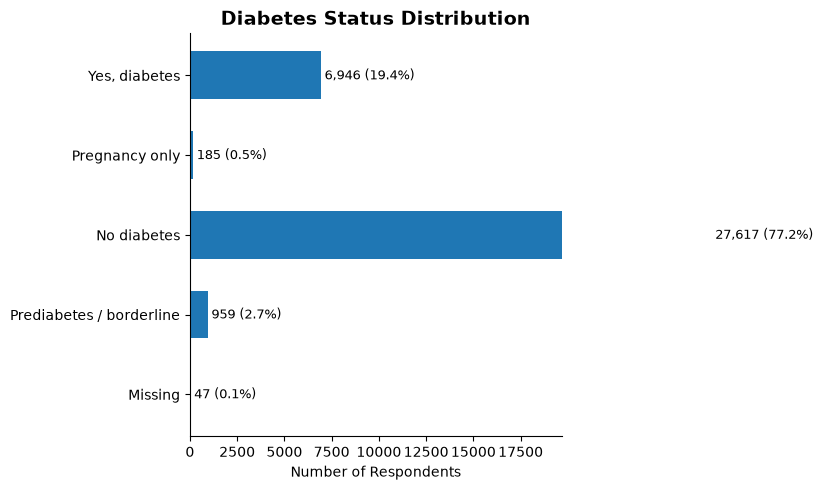


Smoking Status Distribution


,Category,Count,Percentage (%)
0,Current smoker (every day),2865,8.01
1,Current smoker (some days),986,2.76
2,Former smoker,11652,32.59
3,Never smoked,20010,55.97
4,Missing,241,0.67


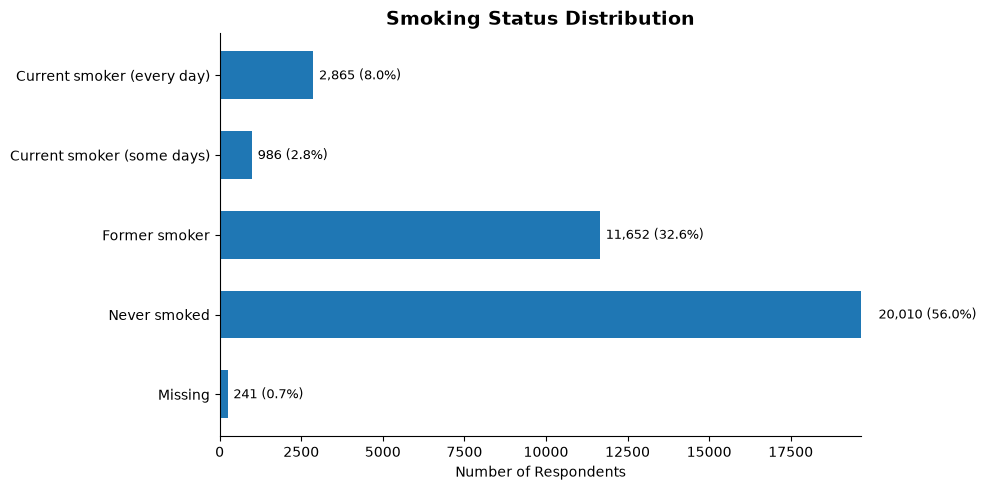

In [30]:

# ==========================================
# EDA 5A. Health Categorical Features
# ==========================================

health_mappings = {

    "_BMI5CAT": {
        1.0: "Underweight",
        2.0: "Normal weight",
        3.0: "Overweight",
        4.0: "Obese"
    },

    "DIABETE4": {
        1.0: "Yes, diabetes",
        2.0: "Pregnancy only",
        3.0: "No diabetes",
        4.0: "Prediabetes / borderline"
    },

    "_SMOKER3": {
        1.0: "Current smoker (every day)",
        2.0: "Current smoker (some days)",
        3.0: "Former smoker",
        4.0: "Never smoked"
    }
}

health_orders = {
    "_BMI5CAT": [
        "Underweight", "Normal weight",
        "Overweight", "Obese", "Missing"
    ],

    "DIABETE4": [
        "Yes, diabetes", "Pregnancy only",
        "No diabetes", "Prediabetes / borderline",
        "Missing"
    ],

    "_SMOKER3": [
        "Current smoker (every day)",
        "Current smoker (some days)",
        "Former smoker", "Never smoked",
        "Missing"
    ]
}

health_titles = {
    "_BMI5CAT": "BMI Category Distribution",
    "DIABETE4": "Diabetes Status Distribution",
    "_SMOKER3": "Smoking Status Distribution"
}

for variable, mapping in health_mappings.items():

    labels = (
        model_data[variable]
        .map(mapping)
        .fillna("Missing")
    )

    summary = (
        labels.value_counts()
        .reindex(health_orders[variable], fill_value=0)
        .rename_axis("Category")
        .reset_index(name="Count")
    )

    summary["Percentage (%)"] = (
        summary["Count"] / len(model_data) * 100
    ).round(2)

    print("\n" + "=" * 50)
    print(health_titles[variable])
    display(summary)

    plot_data = summary.iloc[::-1]

    fig, ax = plt.subplots(figsize=(10, 5))

    bars = ax.barh(
        plot_data["Category"],
        plot_data["Count"],
        height=0.6
    )

    for bar, count, pct in zip(
        bars,
        plot_data["Count"],
        plot_data["Percentage (%)"]
    ):

        ax.text(
            bar.get_width() + len(model_data) * 0.005,
            bar.get_y() + bar.get_height() / 2,
            f"{count:,} ({pct:.1f}%)",
            va="center",
            fontsize=9
        )

    ax.set_title(
        health_titles[variable],
        fontsize=14,
        fontweight="bold"
    )

    ax.set_xlabel("Number of Respondents")
    ax.set_ylabel("")

    ax.set_xlim(0, len(model_data) * 0.55)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()
    plt.show()


Percentages are unweighted and based on valid responses (No + Yes) for each indicator. Missing responses are excluded.
Binary Health and Behavior Summary:


,Feature,No_Count,Yes_or_Active_Count,Missing_Count,Positive_Percentage (%)
0,History of depression,29315,6316,123,17.73
1,History of stroke,33517,2115,122,5.94
2,High blood pressure,16412,19223,119,53.94
3,Physical activity,9885,25780,89,72.28


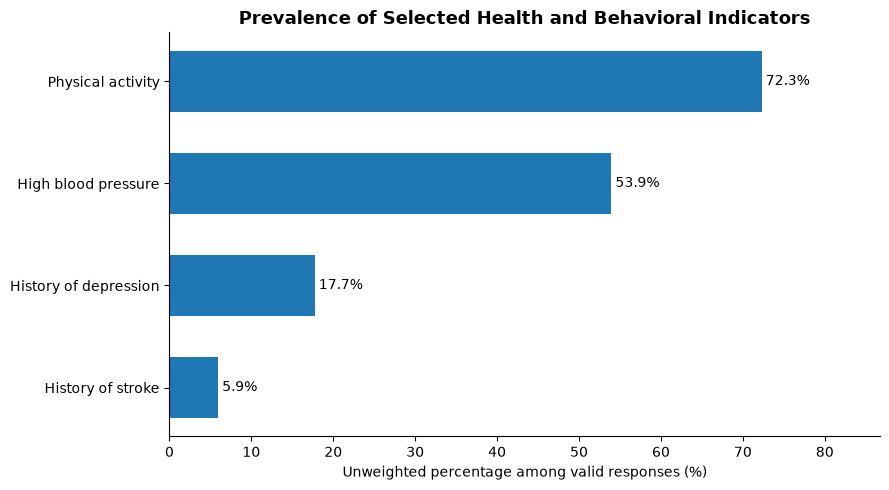

In [31]:

# ==========================================
# EDA 5B. Binary Health and Behavior Features
# ==========================================

binary_health_features = {
    "Depression_bin": "History of depression",
    "Stroke_bin": "History of stroke",
    "HighBP_bin": "High blood pressure",
    "PhysicalActivity_bin": "Physical activity"
}

binary_summary = []
print(
    "Percentages are unweighted and based on valid responses "
    "(No + Yes) for each indicator. Missing responses are excluded."
)

for variable, label in binary_health_features.items():

    no_count = (model_data[variable] == 0).sum()
    yes_count = (model_data[variable] == 1).sum()
    missing_count = model_data[variable].isna().sum()

    valid_count = no_count + yes_count

    yes_percentage = (
        yes_count / valid_count * 100
        if valid_count > 0 else 0
    )

    binary_summary.append({
        "Feature": label,
        "No_Count": no_count,
        "Yes_or_Active_Count": yes_count,
        "Missing_Count": missing_count,
        "Positive_Percentage (%)": round(
            yes_percentage, 2
        )
    })

binary_summary = pd.DataFrame(binary_summary)

print("Binary Health and Behavior Summary:")
display(binary_summary)

# Plot positive / active percentages
plot_data = binary_summary.sort_values(
    "Positive_Percentage (%)"
)

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.barh(
    plot_data["Feature"],
    plot_data["Positive_Percentage (%)"],
    height=0.6
)

for bar in bars:

    ax.text(
        bar.get_width() + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.1f}%",
        va="center",
        fontsize=10
    )

ax.set_title(
    "Prevalence of Selected Health and Behavioral Indicators",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("Unweighted percentage among valid responses (%)")
ax.set_ylabel("")

ax.set_xlim(
    0,
    plot_data["Positive_Percentage (%)"].max() * 1.2
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [32]:

# ==========================================
# Step 6A. Individual ACE Distribution
# ==========================================

ace_features = [
    "ACEDEPRS_bin",
    "ACEDRINK_bin",
    "ACEDRUGS_bin",
    "ACEPRISN_bin",
    "ACEDIVRC_bin",
    "ACEPUNCH_bin",
    "ACEHURT1_bin",
    "ACESWEAR_bin",
    "ACETOUCH_bin",
    "ACETTHEM_bin",
    "ACEHVSEX_bin"
]

# Descriptive labels
ace_labels = {
    "ACEDEPRS_bin": "Household mental illness",
    "ACEDRINK_bin": "Household alcohol problems",
    "ACEDRUGS_bin": "Household drug problems",
    "ACEPRISN_bin": "Household incarceration",
    "ACEDIVRC_bin": "Parental divorce / separation",
    "ACEPUNCH_bin": "Household violence",
    "ACEHURT1_bin": "Physical abuse",
    "ACESWEAR_bin": "Verbal abuse",
    "ACETOUCH_bin": "Unwanted sexual touching",
    "ACETTHEM_bin": "Forced sexual touching",
    "ACEHVSEX_bin": "Forced sex"
}

# Check that all variables exist
missing_columns = [
    col for col in ace_features
    if col not in model_data.columns
]

if missing_columns:
    raise ValueError(
        f"Missing ACE columns: {missing_columns}"
    )

# Check binary encoding
for col in ace_features:
    values = set(model_data[col].dropna().unique())
    if not values.issubset({0, 1, 0.0, 1.0}):
        raise ValueError(
            f"Unexpected values in {col}: {values}"
        )

# Calculate prevalence
ace_results = []

for col in ace_features:

    valid_data = model_data[col].dropna()

    yes_count = (valid_data == 1).sum()
    no_count = (valid_data == 0).sum()
    missing_count = model_data[col].isna().sum()

    valid_count = len(valid_data)

    prevalence = (
        yes_count / valid_count * 100
        if valid_count > 0 else 0
    )

    ace_results.append({
        "ACE Feature": ace_labels[col],
        "Variable": col,
        "Yes_Count": yes_count,
        "No_Count": no_count,
        "Missing_Count": missing_count,
        "Valid_Count": valid_count,
        "Prevalence (%)": round(prevalence, 2)
    })

ace_summary = pd.DataFrame(ace_results)

# Sort by prevalence
ace_summary = ace_summary.sort_values(
    "Prevalence (%)",
    ascending=False
).reset_index(drop=True)

print("Individual ACE Prevalence:")
display(ace_summary)

print("\nTotal sample size:", len(model_data))


Individual ACE Prevalence:


,ACE Feature,Variable,Yes_Count,No_Count,Missing_Count,Valid_Count,Prevalence (%)
0,Verbal abuse,ACESWEAR_bin,10225,25529,0,35754,28.60
1,Physical abuse,ACEHURT1_bin,8616,27138,0,35754,24.10
2,Household alcohol problems,ACEDRINK_bin,7863,27891,0,35754,21.99
3,Parental divorce / separation,ACEDIVRC_bin,7812,27942,0,35754,21.85
4,Household violence,ACEPUNCH_bin,5118,30636,0,35754,14.31
5,Household mental illness,ACEDEPRS_bin,5043,30711,0,35754,14.10
6,Unwanted sexual touching,ACETOUCH_bin,3900,31854,0,35754,10.91
7,Forced sexual touching,ACETTHEM_bin,2834,32920,0,35754,7.93
8,Household drug problems,ACEDRUGS_bin,2529,33225,0,35754,7.07
9,Forced sex,ACEHVSEX_bin,1580,34174,0,35754,4.42



Total sample size: 35754


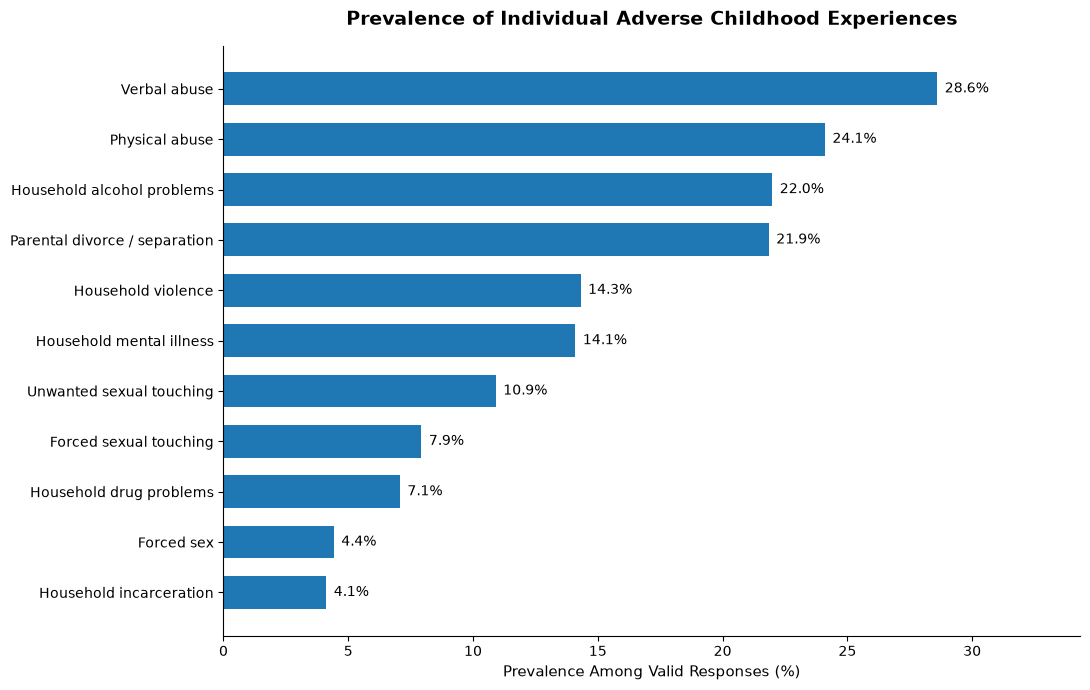

In [33]:

# ==========================================
# Step 6B. ACE Prevalence Visualization
# ==========================================

plot_data = ace_summary.sort_values(
    "Prevalence (%)",
    ascending=True
)

fig, ax = plt.subplots(figsize=(11, 7))

bars = ax.barh(
    plot_data["ACE Feature"],
    plot_data["Prevalence (%)"],
    height=0.65
)

# Add percentage labels
for bar, percentage in zip(
    bars,
    plot_data["Prevalence (%)"]
):

    ax.text(
        bar.get_width() + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"{percentage:.1f}%",
        va="center",
        fontsize=10
    )

ax.set_title(
    "Prevalence of Individual Adverse Childhood Experiences",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel(
    "Prevalence Among Valid Responses (%)",
    fontsize=11
)

ax.set_ylabel("")

ax.set_xlim(
    0,
    plot_data["Prevalence (%)"].max() * 1.2
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


In [34]:

# ==========================================
# Step 8A. Calculate ACE Score
# ==========================================

# Check all 11 ACE variables
assert all(col in model_data.columns for col in ace_features)

# Check missing values
print("Missing values in ACE items:")
print(model_data[ace_features].isna().sum())

# Check binary values
for col in ace_features:
    assert set(model_data[col].unique()).issubset({0, 1, 0.0, 1.0})

# Calculate ACE score for EDA ONLY
ace_score_eda = model_data[ace_features].sum(axis=1)

print("\nACE Score Summary:")
print(ace_score_eda.describe())

print("\nMinimum ACE Score:", ace_score_eda.min())
print("Maximum ACE Score:", ace_score_eda.max())
print("Mean ACE Score:", round(ace_score_eda.mean(), 2))

# Check that original model_data has not been modified
print("\nOriginal model_data shape:", model_data.shape)


Missing values in ACE items:
ACEDEPRS_bin    0
ACEDRINK_bin    0
ACEDRUGS_bin    0
ACEPRISN_bin    0
ACEDIVRC_bin    0
ACEPUNCH_bin    0
ACEHURT1_bin    0
ACESWEAR_bin    0
ACETOUCH_bin    0
ACETTHEM_bin    0
ACEHVSEX_bin    0
dtype: int64

ACE Score Summary:
count    35754.000000
mean         1.594003
std          2.021301
min          0.000000
25%          0.000000
50%          1.000000
75%          2.000000
max         11.000000
dtype: float64

Minimum ACE Score: 0.0
Maximum ACE Score: 11.0
Mean ACE Score: 1.59

Original model_data shape: (35754, 27)


Detailed ACE Score Distribution:


,ACE Score,Count,Percentage (%)
0,0,14342,40.11
1,1,8245,23.06
2,2,4626,12.94
3,3,3023,8.45
4,4,2005,5.61
5,5,1317,3.68
6,6,890,2.49
7,7,578,1.62
8,8,359,1.00
9,9,194,0.54


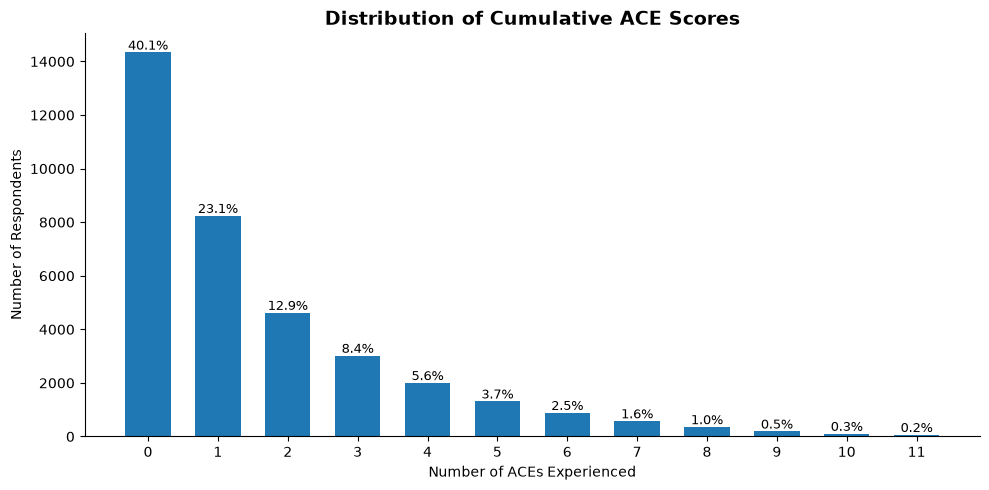

In [35]:

# ==========================================
# Step 8B. Detailed ACE Score Distribution
# ==========================================

score_counts = (
    ace_score_eda.value_counts()
    .reindex(range(12), fill_value=0)
    .sort_index()
)

score_summary = pd.DataFrame({
    "ACE Score": range(12),
    "Count": score_counts.values,
    "Percentage (%)": (
        score_counts.values / len(ace_score_eda) * 100
    ).round(2)
})

print("Detailed ACE Score Distribution:")
display(score_summary)

# Visualization
fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    score_summary["ACE Score"].astype(str),
    score_summary["Count"],
    width=0.65
)

for bar, count, pct in zip(
    bars,
    score_summary["Count"],
    score_summary["Percentage (%)"]
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 100,
        f"{pct:.1f}%",
        ha="center",
        fontsize=9
    )

ax.set_title(
    "Distribution of Cumulative ACE Scores",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Number of ACEs Experienced")
ax.set_ylabel("Number of Respondents")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


Grouped ACE Score Distribution:


,ACE Group,Count,Percentage (%)
0,0 ACE,14342,40.11
1,1 ACE,8245,23.06
2,2-3 ACEs,7649,21.39
3,4+ ACEs,5518,15.43


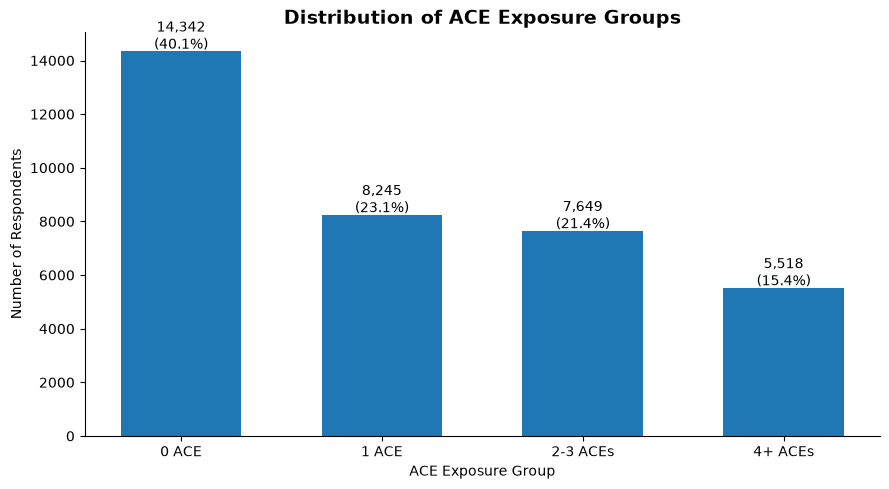

In [36]:

# ==========================================
# Step 8C. Grouped ACE Score Distribution
# ==========================================

ace_groups = pd.cut(
    ace_score_eda,
    bins=[-1, 0, 1, 3, 11],
    labels=["0 ACE", "1 ACE", "2-3 ACEs", "4+ ACEs"]
)

group_counts = (
    ace_groups.value_counts()
    .reindex(["0 ACE", "1 ACE", "2-3 ACEs", "4+ ACEs"])
)

group_summary = pd.DataFrame({
    "ACE Group": group_counts.index,
    "Count": group_counts.values,
    "Percentage (%)": (
        group_counts.values / len(ace_groups) * 100
    ).round(2)
})

print("Grouped ACE Score Distribution:")
display(group_summary)

# Visualization
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    group_summary["ACE Group"],
    group_summary["Count"],
    width=0.6
)

for bar, count, pct in zip(
    bars,
    group_summary["Count"],
    group_summary["Percentage (%)"]
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 100,
        f"{count:,}\n({pct:.1f}%)",
        ha="center",
        fontsize=10
    )

ax.set_title(
    "Distribution of ACE Exposure Groups",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("ACE Exposure Group")
ax.set_ylabel("Number of Respondents")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


In [37]:

# ==========================================
# Step 9A. ACE Groups vs SCD
# Use training data only to avoid data leakage
# ==========================================

# Select training data
train_eda = model_data[
    model_data["Dataset_Split"] == "train"
].copy()

# Calculate ACE score for training data
train_eda["ACE_score_eda"] = (
    train_eda[ace_features].sum(axis=1)
)

# Create ACE groups
train_eda["ACE_Group"] = pd.cut(
    train_eda["ACE_score_eda"],
    bins=[-1, 0, 1, 3, 11],
    labels=["0 ACE", "1 ACE", "2-3 ACEs", "4+ ACEs"]
)

# Calculate SCD prevalence
ace_scd_summary = (
    train_eda.groupby("ACE_Group", observed=False)["SCD"]
    .agg(
        Total="count",
        SCD_Cases="sum",
        SCD_Rate="mean"
    )
)

ace_scd_summary["No_SCD"] = (
    ace_scd_summary["Total"]
    - ace_scd_summary["SCD_Cases"]
)

ace_scd_summary["SCD_Prevalence (%)"] = (
    ace_scd_summary["SCD_Rate"] * 100
).round(2)

ace_scd_summary["No_SCD_Percentage (%)"] = (
    ace_scd_summary["No_SCD"]
    / ace_scd_summary["Total"] * 100
).round(2)

ace_scd_summary = ace_scd_summary[
    [
        "Total",
        "No_SCD",
        "SCD_Cases",
        "No_SCD_Percentage (%)",
        "SCD_Prevalence (%)"
    ]
]

print("SCD Prevalence Across ACE Groups:")
display(ace_scd_summary)


SCD Prevalence Across ACE Groups:


,Total,No_SCD,SCD_Cases,No_SCD_Percentage (%),SCD_Prevalence (%)
ACE_Group,,,,,
0 ACE,11474,10147.0,1327.0,88.43,11.57
1 ACE,6573,5587.0,986.0,85.00,15.00
2-3 ACEs,6101,4844.0,1257.0,79.40,20.60
4+ ACEs,4455,3135.0,1320.0,70.37,29.63


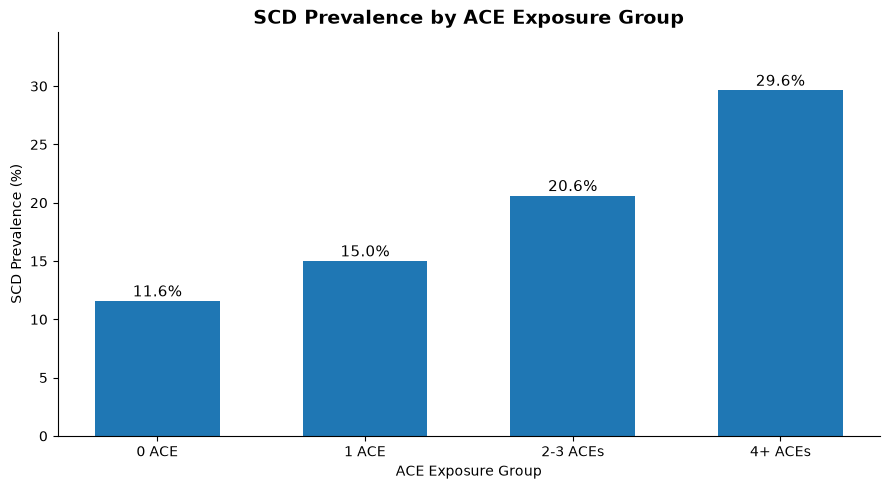

In [38]:

# ==========================================
# Visualization: SCD Prevalence by ACE Group
# ==========================================

plot_data = ace_scd_summary.reset_index()

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    plot_data["ACE_Group"].astype(str),
    plot_data["SCD_Prevalence (%)"],
    width=0.6
)

for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.4,
        f"{height:.1f}%",
        ha="center",
        fontsize=11
    )

ax.set_title(
    "SCD Prevalence by ACE Exposure Group",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("ACE Exposure Group")
ax.set_ylabel("SCD Prevalence (%)")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.set_ylim(
    0,
    plot_data["SCD_Prevalence (%)"].max() + 5
)

plt.tight_layout()
plt.show()


In [39]:
# Step 9B. Individual ACE Items vs SCD
# Training data only

ace_results = []

for feature in ace_features:
    temp = train_eda[[feature, "SCD"]].dropna()

    exposed = temp.loc[temp[feature].eq(1), "SCD"]
    unexposed = temp.loc[temp[feature].eq(0), "SCD"]

    prevalence_yes = exposed.mean() * 100
    prevalence_no = unexposed.mean() * 100

    ace_results.append({
        "ACE_Feature": feature,
        "ACE_Yes_Count": len(exposed),
        "ACE_No_Count": len(unexposed),
        "SCD_Prevalence_Yes (%)": prevalence_yes,
        "SCD_Prevalence_No (%)": prevalence_no,
        "Prevalence_Difference": prevalence_yes - prevalence_no,
    })

ace_results_df = pd.DataFrame(ace_results).sort_values(
    "Prevalence_Difference", ascending=False
)

display(ace_results_df.round(2))
print("Number of ACE items:", len(ace_results_df))

,ACE_Feature,ACE_Yes_Count,ACE_No_Count,SCD_Prevalence_Yes (%),SCD_Prevalence_No (%),Prevalence_Difference
10,ACEHVSEX_bin,1248,27355,35.18,16.27,18.91
9,ACETTHEM_bin,2258,26345,30.96,15.91,15.05
8,ACETOUCH_bin,3104,25499,29.67,15.57,14.11
0,ACEDEPRS_bin,4045,24558,28.63,15.20,13.43
3,ACEPRISN_bin,1161,27442,28.94,16.60,12.35
2,ACEDRUGS_bin,2025,26578,27.95,16.27,11.68
5,ACEPUNCH_bin,4114,24489,25.89,15.62,10.27
6,ACEHURT1_bin,6895,21708,24.77,14.66,10.11
7,ACESWEAR_bin,8174,20429,24.16,14.27,9.89
1,ACEDRINK_bin,6330,22273,24.01,15.13,8.88


Number of ACE items: 11


In [40]:
# ==========================================
# Step 9C. Demographic & Socioeconomic Features
# ==========================================

eda_9c = train_eda.copy()

# Create age groups for descriptive analysis
eda_9c["Age_Group"] = pd.cut(
    eda_9c["_AGE80"],
    bins=[44, 54, 64, 74, 80],
    labels=["45-54", "55-64", "65-74", "75+"]
)

# Category labels
sex_map = {
    0: "Male",
    1: "Female"
}

race_map = {
    1: "White, non-Hispanic",
    2: "Black, non-Hispanic",
    3: "Other race, non-Hispanic",
    4: "Multiracial, non-Hispanic",
    5: "Hispanic"
}

state_map = {
    10: "Delaware",
    12: "Florida",
    13: "Georgia",
    29: "Missouri",
    32: "Nevada",
    34: "New Jersey",
    41: "Oregon",
    44: "Rhode Island",
    47: "Tennessee",
    51: "Virginia"
}

education_map = {
    1: "No schooling / Kindergarten",
    2: "Grades 1-8",
    3: "Grades 9-11",
    4: "High school / GED",
    5: "Some college / Technical school",
    6: "College graduate"
}

income_map = {
    1: "< $10,000",
    2: "$10,000-$14,999",
    3: "$15,000-$19,999",
    4: "$20,000-$24,999",
    5: "$25,000-$34,999",
    6: "$35,000-$49,999",
    7: "$50,000-$74,999",
    8: "$75,000-$99,999",
    9: "$100,000-$149,999",
    10: "$150,000-$199,999",
    11: "$200,000+"
}

marital_map = {
    1: "Married",
    2: "Divorced",
    3: "Widowed",
    4: "Separated",
    5: "Never married",
    6: "Unmarried couple"
}

# Combine education categories

education_group_map = {
    1: "High school or less",
    2: "High school or less",
    3: "High school or less",
    4: "High school or less",
    5: "Some college / Technical school",
    6: "College graduate"
}

eda_9c["Education_Group"] = (
    eda_9c["EDUCA"].map(education_group_map)
)

print("Education Group Distribution:")
print(eda_9c["Education_Group"].value_counts(dropna=False))

feature_specs = {
    "Sex": ("SEXVAR", sex_map),
    "Age": ("Age_Group", None),
    "Race/Ethnicity": ("_RACEGR3", race_map),
    "State": ("_STATE", state_map),
    "Education": ("Education_Group", None),
    "Income": ("INCOME3", income_map),
    "Marital Status": ("MARITAL", marital_map)
}

print("Training dataset:", eda_9c.shape)
print("Features to analyze:", len(feature_specs))


Education Group Distribution:
Education_Group
College graduate                   12923
High school or less                 8197
Some college / Technical school     7404
NaN                                   79
Name: count, dtype: int64
Training dataset: (28603, 31)
Features to analyze: 7


In [41]:
# ==========================================
# Calculate SCD prevalence by each feature
# ==========================================

from scipy.stats import chi2_contingency

demo_results = []
demo_test_results = []

for feature_name, (variable, mapping) in feature_specs.items():

    temp = eda_9c[[variable, "SCD"]].dropna().copy()

    # Convert codes to category labels
    if mapping is not None:
        temp["Category"] = temp[variable].map(mapping)
        temp["Category"] = temp["Category"].fillna(
            temp[variable].astype(str)
        )
    else:
        temp["Category"] = temp[variable].astype(str)

    # Sort categories
    temp = temp.sort_values(variable)

    # Calculate group statistics
    summary = (
        temp.groupby("Category", sort=False)
        .agg(
            Total=("SCD", "count"),
            SCD_Cases=("SCD", "sum"),
            SCD_Prevalence=("SCD", "mean")
        )
        .reset_index()
    )

    summary["No_SCD"] = (
        summary["Total"] - summary["SCD_Cases"]
    )

    summary["SCD_Prevalence (%)"] = (
        summary["SCD_Prevalence"] * 100
    ).round(2)

    # Chi-square test
    contingency = pd.crosstab(
        temp["Category"],
        temp["SCD"]
    )

    chi2, p_value, dof, expected = chi2_contingency(
        contingency
    )

    demo_results.append({
        "Feature": feature_name,
        "Category_Summary": summary
    })

    demo_test_results.append({
        "Feature": feature_name,
        "Valid_N": len(temp),
        "Missing_N": len(eda_9c) - len(temp),
        "Chi2": chi2,
        "P_Value": p_value,
        "Min_Expected_Count": expected.min()
    })

    print("\n" + "=" * 60)
    print(feature_name)
    display(summary)

# Overall test results
demo_test_df = pd.DataFrame(demo_test_results)

# Holm correction across 7 overall tests
p = demo_test_df["P_Value"].values
order = np.argsort(p)
m = len(p)

adjusted = np.maximum.accumulate(
    (m - np.arange(m)) * p[order]
)

holm = np.empty(m)
holm[order] = np.minimum(adjusted, 1)

demo_test_df["Holm_P_Value"] = holm

print("\nOverall Chi-square Test Results:")
display(demo_test_df.round(5))



Sex


,Category,Total,SCD_Cases,SCD_Prevalence,No_SCD,SCD_Prevalence (%)
0,Male,12515,2033.0,0.162445,10482.0,16.24
1,Female,16088,2857.0,0.177586,13231.0,17.76



Age


,Category,Total,SCD_Cases,SCD_Prevalence,No_SCD,SCD_Prevalence (%)
0,45-54,5107,816.0,0.159781,4291.0,15.98
1,55-64,7218,1218.0,0.168745,6000.0,16.87
2,65-74,8841,1376.0,0.155639,7465.0,15.56
3,75+,7437,1480.0,0.199005,5957.0,19.90



Race/Ethnicity


,Category,Total,SCD_Cases,SCD_Prevalence,No_SCD,SCD_Prevalence (%)
0,"White, non-Hispanic",22891,3888.0,0.169848,19003.0,16.98
1,"Black, non-Hispanic",2664,423.0,0.158784,2241.0,15.88
2,"Other race, non-Hispanic",742,133.0,0.179245,609.0,17.92
3,"Multiracial, non-Hispanic",479,103.0,0.215031,376.0,21.50
4,Hispanic,1321,245.0,0.185466,1076.0,18.55


... (6 outputs left out)


Marital Status


,Category,Total,SCD_Cases,SCD_Prevalence,No_SCD,SCD_Prevalence (%)
0,Married,16058,2403.0,0.149645,13655.0,14.96
1,Divorced,4370,954.0,0.218307,3416.0,21.83
2,Widowed,4774,924.0,0.193548,3850.0,19.35
3,Separated,484,134.0,0.276860,350.0,27.69
4,Never married,2145,346.0,0.161305,1799.0,16.13
5,Unmarried couple,605,106.0,0.175207,499.0,17.52



Overall Chi-square Test Results:


,Feature,Valid_N,Missing_N,Chi2,P_Value,Min_Expected_Count,Holm_P_Value
0,Sex,28603,0,11.27865,0.00078,2139.57802,0.00157
1,Age,28603,0,60.66629,0.00000,873.09828,0.00000
2,Race/Ethnicity,28097,506,11.86036,0.01842,81.69442,0.01842
3,State,28603,0,92.67084,0.00000,185.49278,0.00000
4,Education,28524,79,167.36184,0.00000,1265.92722,0.00000
5,Income,23488,5115,562.01957,0.00000,81.50681,0.00000
6,Marital Status,28436,167,177.39358,0.00000,82.83964,0.00000


In [42]:
# ==========================================
# Step 9D. Health & Behavioral Features
# ==========================================

eda_9d = train_eda.copy()

# Check required variables
required_cols = [
    "SCD",
    "Depression_bin",
    "Stroke_bin",
    "HighBP_bin",
    "DIABETE4",
    "_BMI5CAT",
    "_SMOKER3",
    "PhysicalActivity_bin"
]

missing_cols = [
    col for col in required_cols
    if col not in eda_9d.columns
]

print("Training dataset:", eda_9d.shape)
print("Missing columns:", missing_cols)

print("\nMissing values:")
print(eda_9d[required_cols].isna().sum())


Training dataset: (28603, 29)
Missing columns: []

Missing values:
SCD                        0
Depression_bin           103
Stroke_bin                98
HighBP_bin                92
DIABETE4                  37
_BMI5CAT                1448
_SMOKER3                 187
PhysicalActivity_bin      74
dtype: int64


In [43]:
# ==========================================
# Define category labels
# ==========================================

feature_specs = {

    "Depression": (
        "Depression_bin",
        {0: "No", 1: "Yes"}
    ),

    "Stroke": (
        "Stroke_bin",
        {0: "No", 1: "Yes"}
    ),

    "High Blood Pressure": (
        "HighBP_bin",
        {0: "No", 1: "Yes"}
    ),

    "Diabetes": (
        "DIABETE4",
        {
            1: "Yes, diabetes",
            2: "Pregnancy only",
            3: "No diabetes",
            4: "Prediabetes / borderline"
        }
    ),

    "BMI Category": (
        "_BMI5CAT",
        {
            1: "Underweight",
            2: "Normal weight",
            3: "Overweight",
            4: "Obese"
        }
    ),

    "Smoking Status": (
        "_SMOKER3",
        {
            1: "Current smoker (every day)",
            2: "Current smoker (some days)",
            3: "Former smoker",
            4: "Never smoked"
        }
    ),

    "Physical Activity": (
        "PhysicalActivity_bin",
        {0: "Inactive", 1: "Active"}
    )
}

print("Number of features:", len(feature_specs))


Number of features: 7


In [44]:
# ==========================================
# Calculate SCD prevalence by health features
# ==========================================

from scipy.stats import chi2_contingency

health_results = []
health_test_results = []

for feature_name, (variable, mapping) in feature_specs.items():

    temp = eda_9d[[variable, "SCD"]].copy()

    # Convert category codes into readable labels
    temp["Category"] = temp[variable].map(mapping)

    # Remove missing or invalid responses
    temp = temp.dropna(subset=["Category", "SCD"])

    temp["SCD"] = temp["SCD"].astype(int)

    # Preserve the intended category order
    temp["Category"] = pd.Categorical(
        temp["Category"],
        categories=list(mapping.values()),
        ordered=True
    )

    # Calculate group statistics
    summary = (
        temp.groupby("Category", observed=True)
        .agg(
            Total=("SCD", "count"),
            SCD_Cases=("SCD", "sum"),
            SCD_Prevalence=("SCD", "mean")
        )
        .reset_index()
    )

    summary["No_SCD"] = (
        summary["Total"] - summary["SCD_Cases"]
    )

    summary["SCD_Prevalence (%)"] = (
        summary["SCD_Prevalence"] * 100
    ).round(2)

    # Chi-square test
    contingency = pd.crosstab(
        temp["Category"],
        temp["SCD"]
    )

    chi2, p_value, dof, expected = chi2_contingency(
        contingency
    )

    # Save descriptive results
    health_results.append({
        "Feature": feature_name,
        "Category_Summary": summary
    })

    # Save statistical test results
    health_test_results.append({
        "Feature": feature_name,
        "Valid_N": len(temp),
        "Missing_N": len(eda_9d) - len(temp),
        "Chi2": chi2,
        "P_Value": p_value,
        "Min_Expected_Count": expected.min()
    })

    print("\n" + "=" * 60)
    print(feature_name)
    display(summary)



Depression


,Category,Total,SCD_Cases,SCD_Prevalence,No_SCD,SCD_Prevalence (%)
0,No,23471,2994,0.127562,20477,12.76
1,Yes,5029,1861,0.370054,3168,37.01



Stroke


,Category,Total,SCD_Cases,SCD_Prevalence,No_SCD,SCD_Prevalence (%)
0,No,26823,4329,0.161391,22494,16.14
1,Yes,1682,518,0.307967,1164,30.80



High Blood Pressure


,Category,Total,SCD_Cases,SCD_Prevalence,No_SCD,SCD_Prevalence (%)
0,No,13136,1959,0.149132,11177,14.91
1,Yes,15375,2922,0.190049,12453,19.00


... (4 outputs left out)


Smoking Status


,Category,Total,SCD_Cases,SCD_Prevalence,No_SCD,SCD_Prevalence (%)
0,Current smoker (every day),2306,562,0.243712,1744,24.37
1,Current smoker (some days),779,193,0.247754,586,24.78
2,Former smoker,9376,1842,0.196459,7534,19.65
3,Never smoked,15955,2264,0.141899,13691,14.19



Physical Activity


,Category,Total,SCD_Cases,SCD_Prevalence,No_SCD,SCD_Prevalence (%)
0,Inactive,7950,1895,0.238365,6055,23.84
1,Active,20579,2979,0.144759,17600,14.48


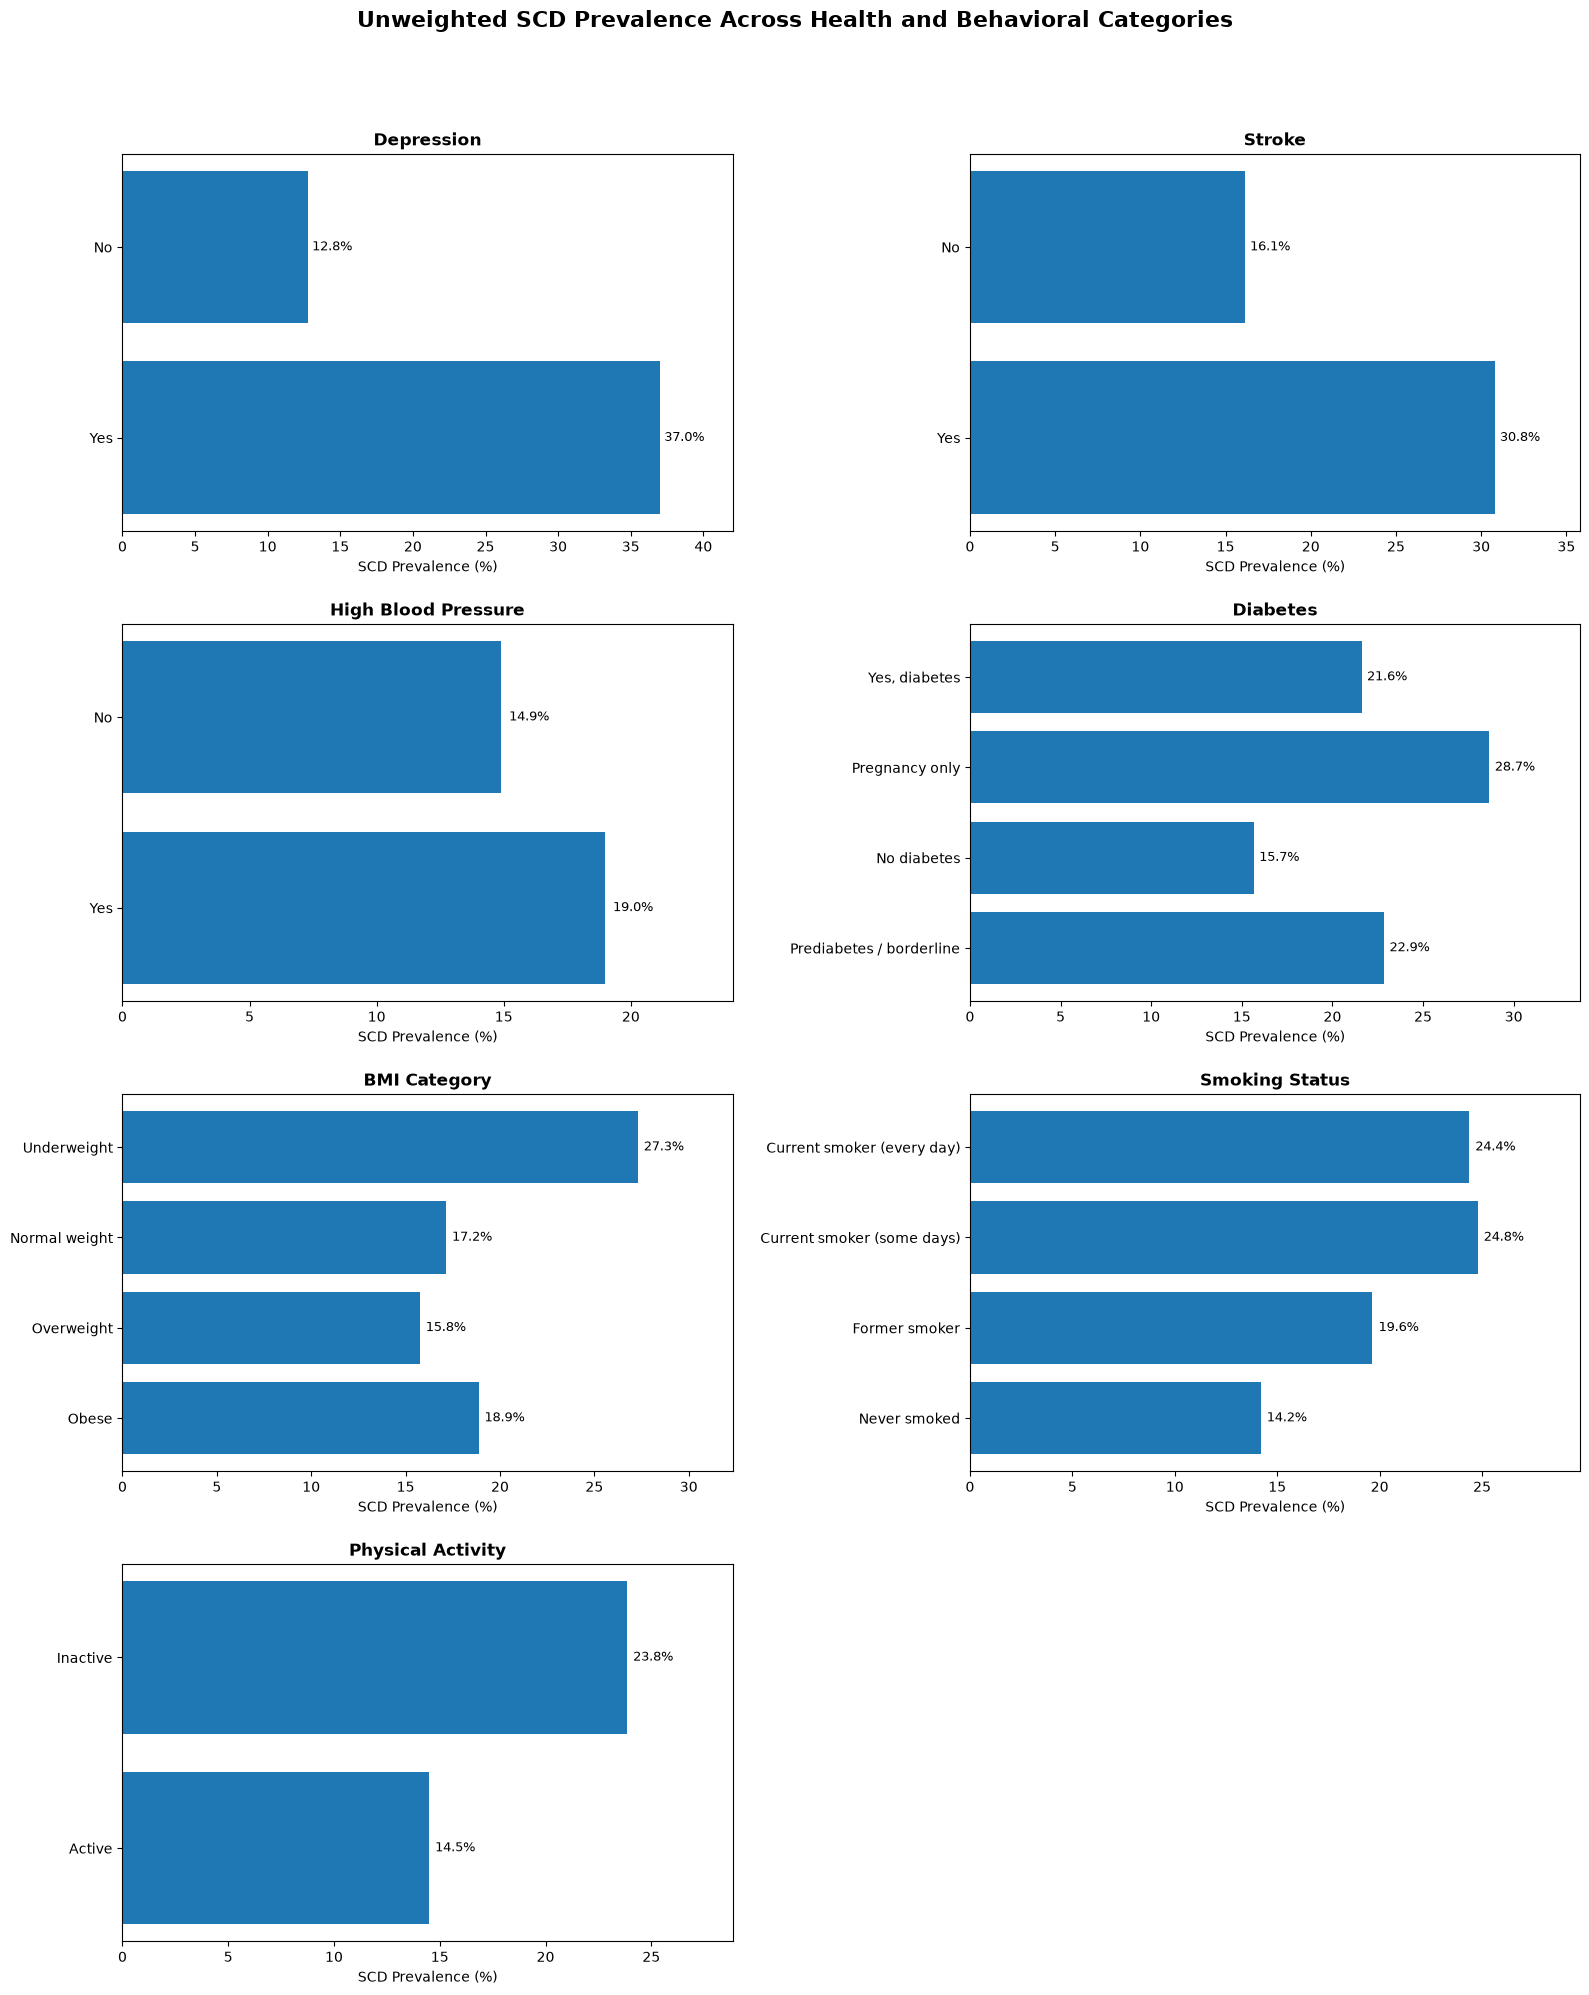

In [45]:

# ==========================================
# Visualize SCD prevalence by health features
# ==========================================

import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    4, 2,
    figsize=(16, 20)
)

axes = axes.flatten()

for i, result in enumerate(health_results):

    summary = result["Category_Summary"]

    ax = axes[i]

    ax.barh(
        summary["Category"].astype(str),
        summary["SCD_Prevalence (%)"]
    )

    ax.set_title(result["Feature"], fontsize=12,
                 fontweight="bold")

    ax.set_xlabel("SCD Prevalence (%)")

    ax.set_xlim(
    0,
    summary["SCD_Prevalence (%)"].max() + 5
    )
    
    ax.invert_yaxis()

    # Add percentage labels
    for j, value in enumerate(
        summary["SCD_Prevalence (%)"]
    ):
        ax.text(
            value + 0.3,
            j,
            f"{value:.1f}%",
            va="center",
            fontsize=9
        )

# Remove the unused eighth subplot
fig.delaxes(axes[7])

fig.suptitle(
    "Unweighted SCD Prevalence Across Health and Behavioral Categories",
    fontsize=16,
    fontweight="bold",
    y=0.995
)

fig.tight_layout(
    rect=[0, 0, 1, 0.96],
    h_pad=2.0,
    w_pad=2.0
)

plt.show()